# Human vs. AI Text Classification — project notebook

CSCE 478/878. This single notebook covers rubric steps 1–4 for both datasets.

**Problem.** Given a short text, predict whether a human or an AI wrote it. This is **binary
classification**. The target is `Label` (0 = Human, 1 = AI). Every model input is computed
from the text alone.

**Questions we want to answer**
- Can simple, explainable statistics of a text separate human writing from AI writing?
- Which text properties carry that signal?
- Does the result hold for writing the model has never seen: new templates, and a different, multi-domain corpus (M4)?

| Part | Rubric step | Dataset |
| --- | --- | --- |
| 1. Problem and data understanding | 1 (10 pts) | Original 50k benchmark |
| 2. Preprocessing and exploration | 2 (15 pts) | Original 50k benchmark |
| 3. Model development | 3 (20 pts) | Original 50k benchmark |
| 4. Evaluation, comparison, recommendation | 4 (20 pts) | Original 50k benchmark |
| 5. Second dataset: M4 | 1–4 again | M4, 93k texts, 5 domains |
| 6. Conclusions | | Both |

**How to run.** From the repository root: `python run.py original` builds the data and models for
Parts 1–4 (about 5–15 minutes). Part 5 reads the committed results in `reports/m4/`, so it runs
without the hour-long M4 pipeline (`python run.py m4` rebuilds them). The heavy work is in tested
scripts under `src/`; this notebook calls them or reads what they wrote, so the numbers here and in
the scripts always agree.

In [1]:
import json
import warnings
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

# tqdm (imported by kagglehub) warns that Jupyter widgets are missing; harmless here.
warnings.filterwarnings("ignore", message="IProgress not found")

# Works whether Jupyter starts in the repo root or in notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

FIGURES = ROOT / "reports" / "figures"
METRICS = ROOT / "reports" / "metrics"
M4 = ROOT / "reports" / "m4"
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 140)


def show(name: str, width: int = 800, folder: Path = FIGURES) -> None:
    """Display a saved figure (default folder: reports/figures)."""
    display(Image(filename=str(folder / name), width=width))

# True retrains both original models from scratch (about 3 minutes); False loads the saved results.
RETRAIN = False

## Part 1. Problem definition and data understanding

**Rubric section:** Problem Definition and Data Understanding (10 pts).

### Dataset and source

Kaggle: [`datascikhan/ai-vs-human-text-classification-benchmark-50k`](https://www.kaggle.com/datasets/datascikhan/ai-vs-human-text-classification-benchmark-50k), version 1.
`python src/prepare_data.py` downloads it to `data/raw/`. The raw file is never edited.

In [2]:
from data_loader import RAW_CSV_PATH

raw = pd.read_csv(RAW_CSV_PATH)
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}")
raw.head(3)

Rows: 50,000   Columns: 30


,Text_ID,Raw_Text,Label,Source_Model,Model_Size,Model_Temperature,Generation_Prompt_Type,RAG_Context_Provided,Detection_Score_Benchmark_Model_A,Word_Count,...,Stopword_Density,Flesch_Kincaid_Grade_Level,Smog_Index,Average_Syllables_Per_Word,Contains_Code_Snippet,Capital_Letter_Count,Formal_Tone_Score,Emotion_Tone_Intensity,Coherence_Score,Burstiness_Score
0,TXT_09927,History has always been a subject of intense debate. Some argue that history...,0,Human_Origin,Human,NaN,Human_Writing,Human,21.510198,219,...,0.438356,11.785556,12.522536,2.027397,0,28,100.000000,16.518485,81.544039,48.832741
1,TXT_35284,"When it comes Similarly, Philosophy, there are several schools of thought. T...",0,Human_Origin,Human,NaN,Human_Writing,Human,78.303093,293,...,0.457338,11.612546,11.958738,2.000000,0,37,100.000000,23.965492,93.325738,65.352863
2,TXT_27383,Let me tell you about Programming. It's one of those topics that everyone ha...,0,Human_Origin,Human,NaN,Human_Writing,Human,83.110976,161,...,0.496894,11.031269,12.423615,1.850932,0,20,91.519314,31.751173,57.563496,58.196010


### Column types and missing values

In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "missing_%": (100 * raw.isna().mean()).round(2),
    "unique_values": raw.nunique(),
})
overview

,dtype,missing,missing_%,unique_values
Text_ID,str,0,0.0,50000
Raw_Text,str,0,0.0,50000
Label,int64,0,0.0,2
Source_Model,str,0,0.0,6
Model_Size,str,0,0.0,4
Model_Temperature,float64,25000,50.0,91
Generation_Prompt_Type,str,0,0.0,11
RAG_Context_Provided,str,0,0.0,3
Detection_Score_Benchmark_Model_A,float64,0,0.0,48107
Word_Count,int64,0,0.0,886


### Class balance

In [4]:
balance = raw["Label"].map({0: "Human", 1: "AI"}).value_counts().to_frame("rows")
balance["share"] = (balance["rows"] / len(raw)).round(3)
balance

,rows,share
Label,,
Human,25000,0.5
AI,25000,0.5


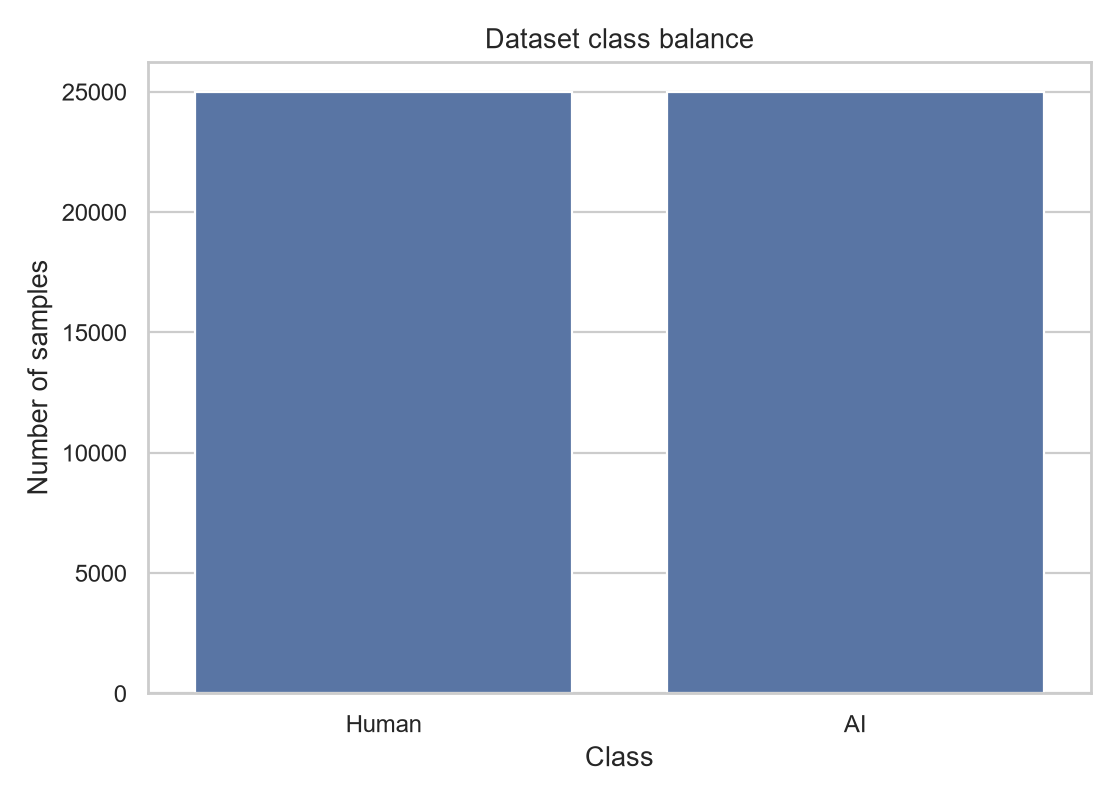

In [5]:
show("class_balance.png", 500)

The classes are exactly balanced (25,000 each), so accuracy is a meaningful metric
and no class weighting or resampling is needed.

### Duplicates

In [6]:
print("Duplicate Text_ID values:", raw["Text_ID"].duplicated().sum())
print("Exact duplicate texts:   ", raw["Raw_Text"].duplicated().sum())

Duplicate Text_ID values: 0
Exact duplicate texts:    0


There are no exact duplicates. Near-duplicates (texts that are almost the same)
are handled in Part 2, because they could leak between training and test sets.

### Data-quality concerns: columns that give the answer away

Some metadata columns describe how the dataset was built, not the text itself.
They separate the classes perfectly, so a model using them would be cheating.

In [7]:
pd.crosstab(raw["Source_Model"], raw["Label"].map({0: "Human", 1: "AI"}))

Label,AI,Human
Source_Model,,
ChatGPT-4o,4963,0
Claude-3.5-Sonnet,4923,0
Gemini-1.5-Pro,5028,0
Human_Origin,0,25000
Llama-3-70B,5014,0
Mistral-Large,5072,0


In [8]:
missing_by_class = raw.groupby(raw["Label"].map({0: "Human", 1: "AI"}))[
    ["Model_Temperature", "Model_Size"]
].apply(lambda g: g.isna().mean().round(3))
missing_by_class

,Model_Temperature,Model_Size
Label,,
AI,0.0,0.0
Human,1.0,0.0


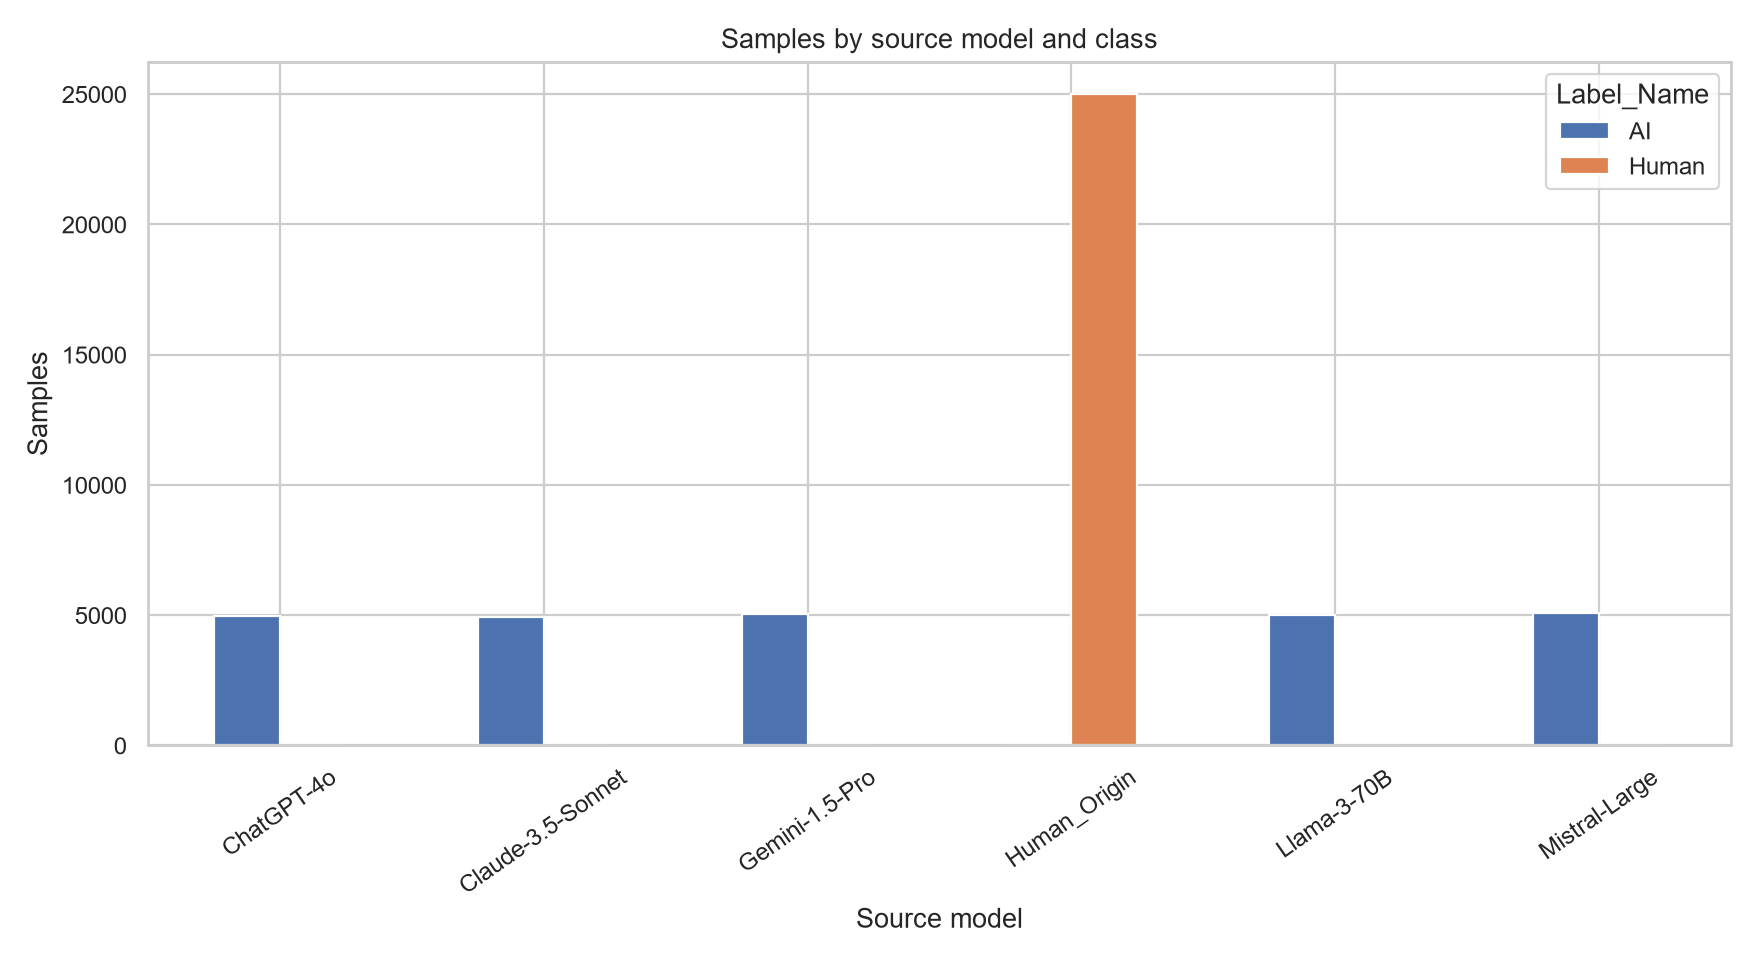

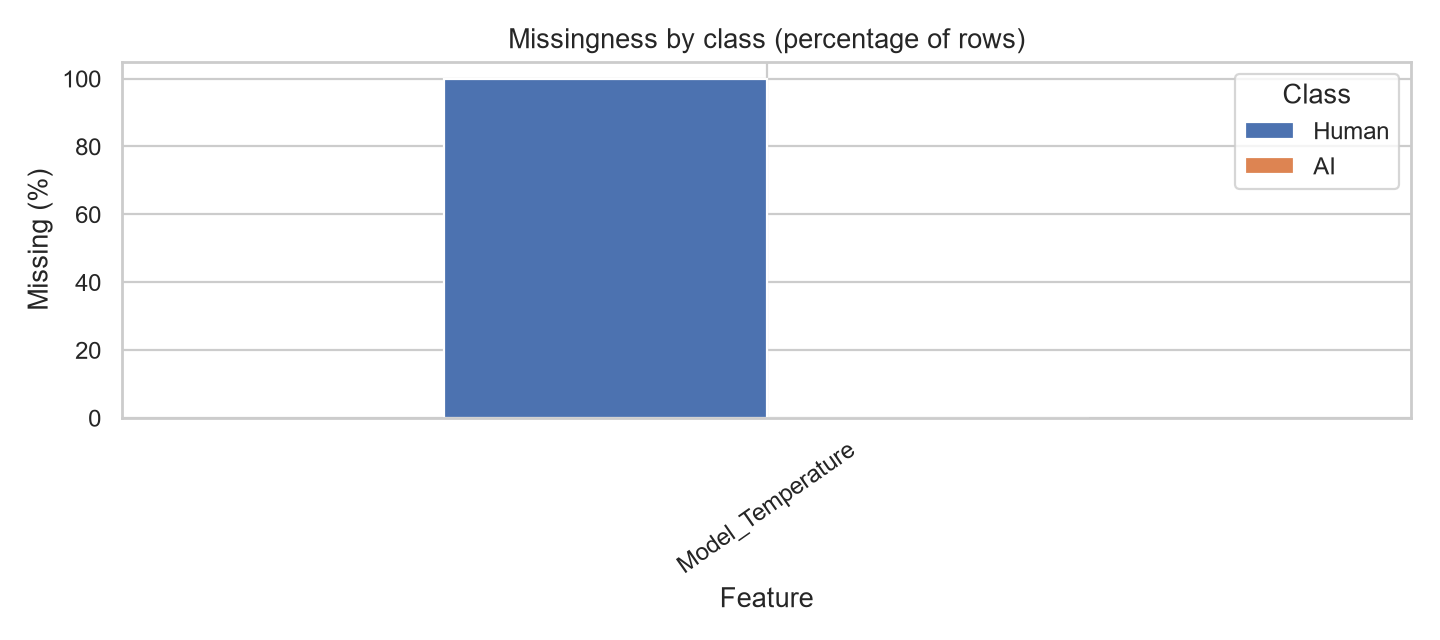

In [9]:
show("source_model_by_class.png", 650)
show("missingness_by_class.png", 650)

- `Source_Model` is `Human_Origin` for every human row, so it **is** the label.
- `Model_Temperature` and `Model_Size` are missing only for human rows, so missingness also reveals the label.
- `Contains_Code_Snippet` is constant, so it carries no information.

**Decision (owner-approved):** dataset-construction metadata is excluded from model inputs.

### The benchmark's own detector score

`Detection_Score_Benchmark_Model_A` is a score from an existing detector. We keep it
only as an external **reference** to compare against, never as an input.

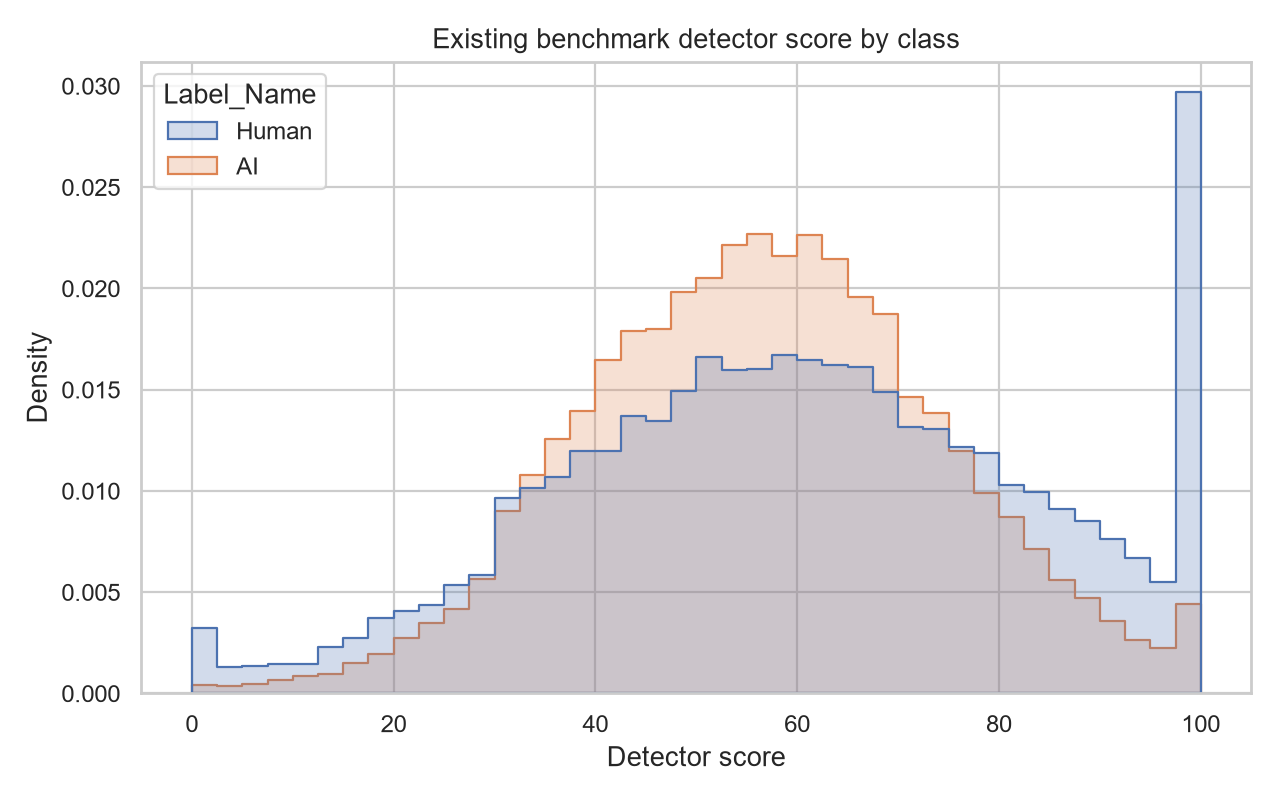

In [10]:
show("detector_score_by_class.png", 650)

### The precomputed `Formal_Tone_Score`

This score has an unexplained ceiling pattern that differs by class, and tone is easy
to change by prompting a model. It is excluded from the initial feature policy
(see `docs/formal_tone_score.md`).

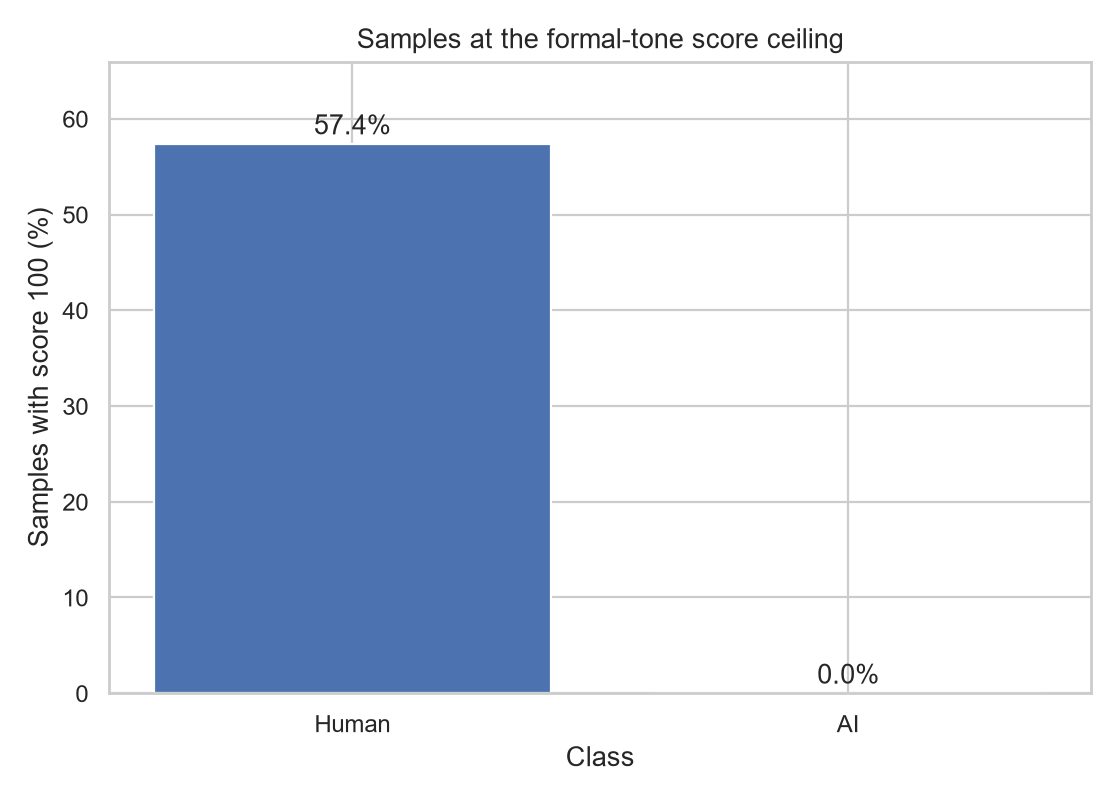

In [11]:
show("formal_tone_score_ceiling.png", 650)

### Text length by class

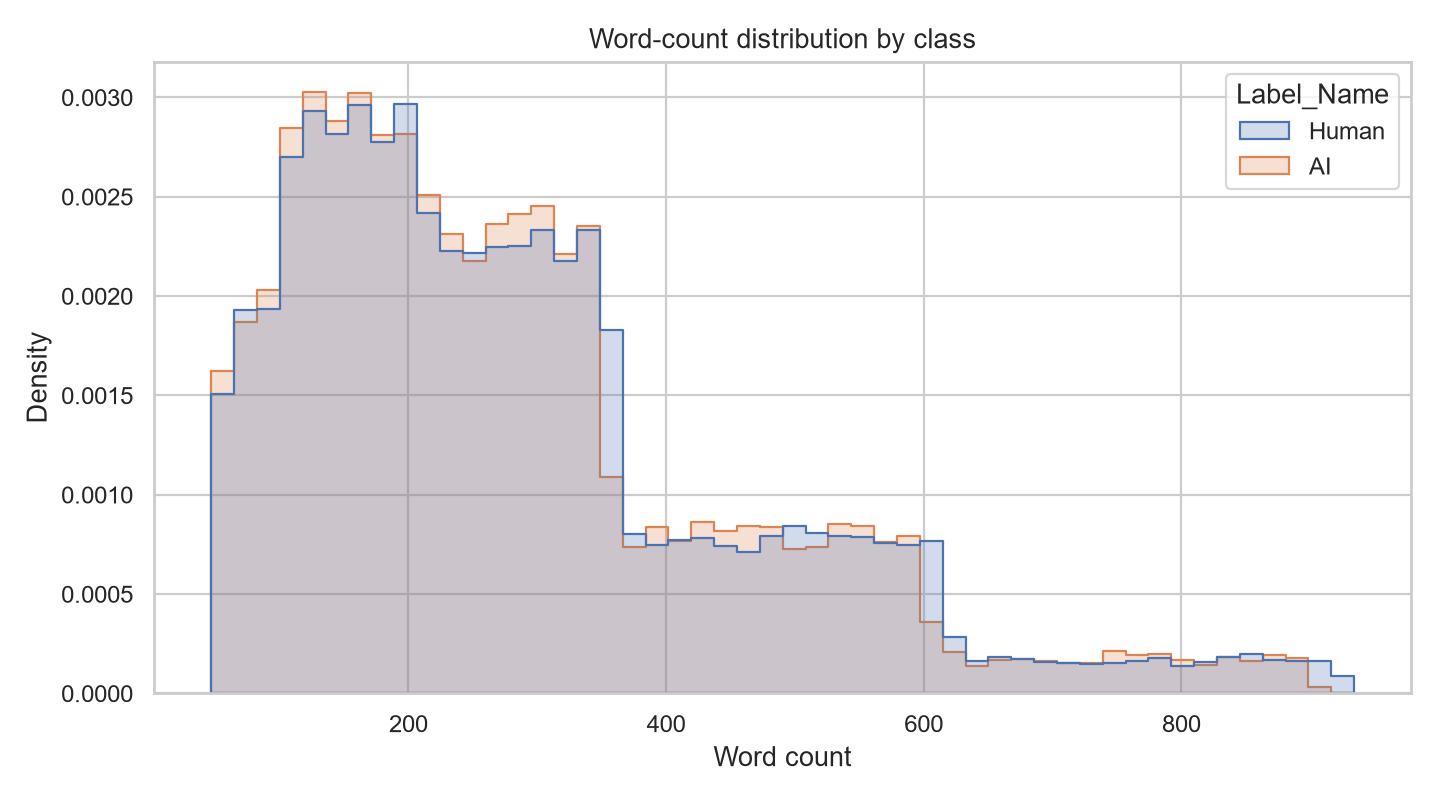

In [12]:
show("word_count_by_class.png", 650)

### Why machine learning

There is no simple written rule that separates human and AI text. We have 50,000
labeled examples, so a model can learn the boundary from data, and we can measure
how well it generalizes on held-out texts.

### Summary of limitations found so far
- The source does not document how its precomputed feature columns were calculated,
  so we **re-derive our own features from `Raw_Text`** (Part 2).
- Metadata columns leak the label and are excluded.
- Part 2 shows that the texts come from only **11 writing templates**, which limits
  how far the results generalize.

## Part 2. Data preprocessing and exploration

**Rubric section:** Data Preprocessing and Exploration (15 pts).

This part covers:
1. Building our own features from the text itself.
2. Removing redundant features.
3. Finding near-duplicate texts and template families.
4. Creating a train/test split that can't leak.

The heavy steps are scripts, run by `python run.py original`. This part reads what they wrote and
explains each decision.

### Step 1: Features come from the text only

**Rule (owner-approved):** every model input must be computable from the submitted text alone.
`src/text_features.py` computes each feature with a documented formula
(see `docs/feature_derivation_spec.md`). Here it is on one sentence:

In [13]:
from text_features import extract_text_features
from prepare_final_data import FINAL_FEATURE_COLUMNS

example = "The quick brown fox jumps over the lazy dog. It was not amused, frankly!"
pd.Series({k: v for k, v in extract_text_features(example).items() if k in FINAL_FEATURE_COLUMNS})

Text_Word_Count                       14.000000
Text_Guiraud_Root_TTR                  3.474396
Text_Average_Word_Length               4.000000
Text_Average_Sentence_Length_Words     7.000000
Text_Punctuation_Density               0.041667
Text_Flesch_Kincaid_Grade_Level        3.154286
Text_Burstiness                       -0.555556
dtype: float64

### Step 2: Keep one feature from each signal family

The full candidate set has many redundant features (for example, raw counts that rise
together with text length). We keep one representative per family:

| Kept feature | Signal family |
| --- | --- |
| `Text_Word_Count` | length |
| `Text_Average_Word_Length` | word complexity |
| `Text_Average_Sentence_Length_Words` | sentence complexity |
| `Text_Guiraud_Root_TTR` | vocabulary variety |
| `Text_Punctuation_Density` | punctuation style |
| `Text_Flesch_Kincaid_Grade_Level` | readability (already includes syllables) |
| `Text_Burstiness` | variation in sentence length |

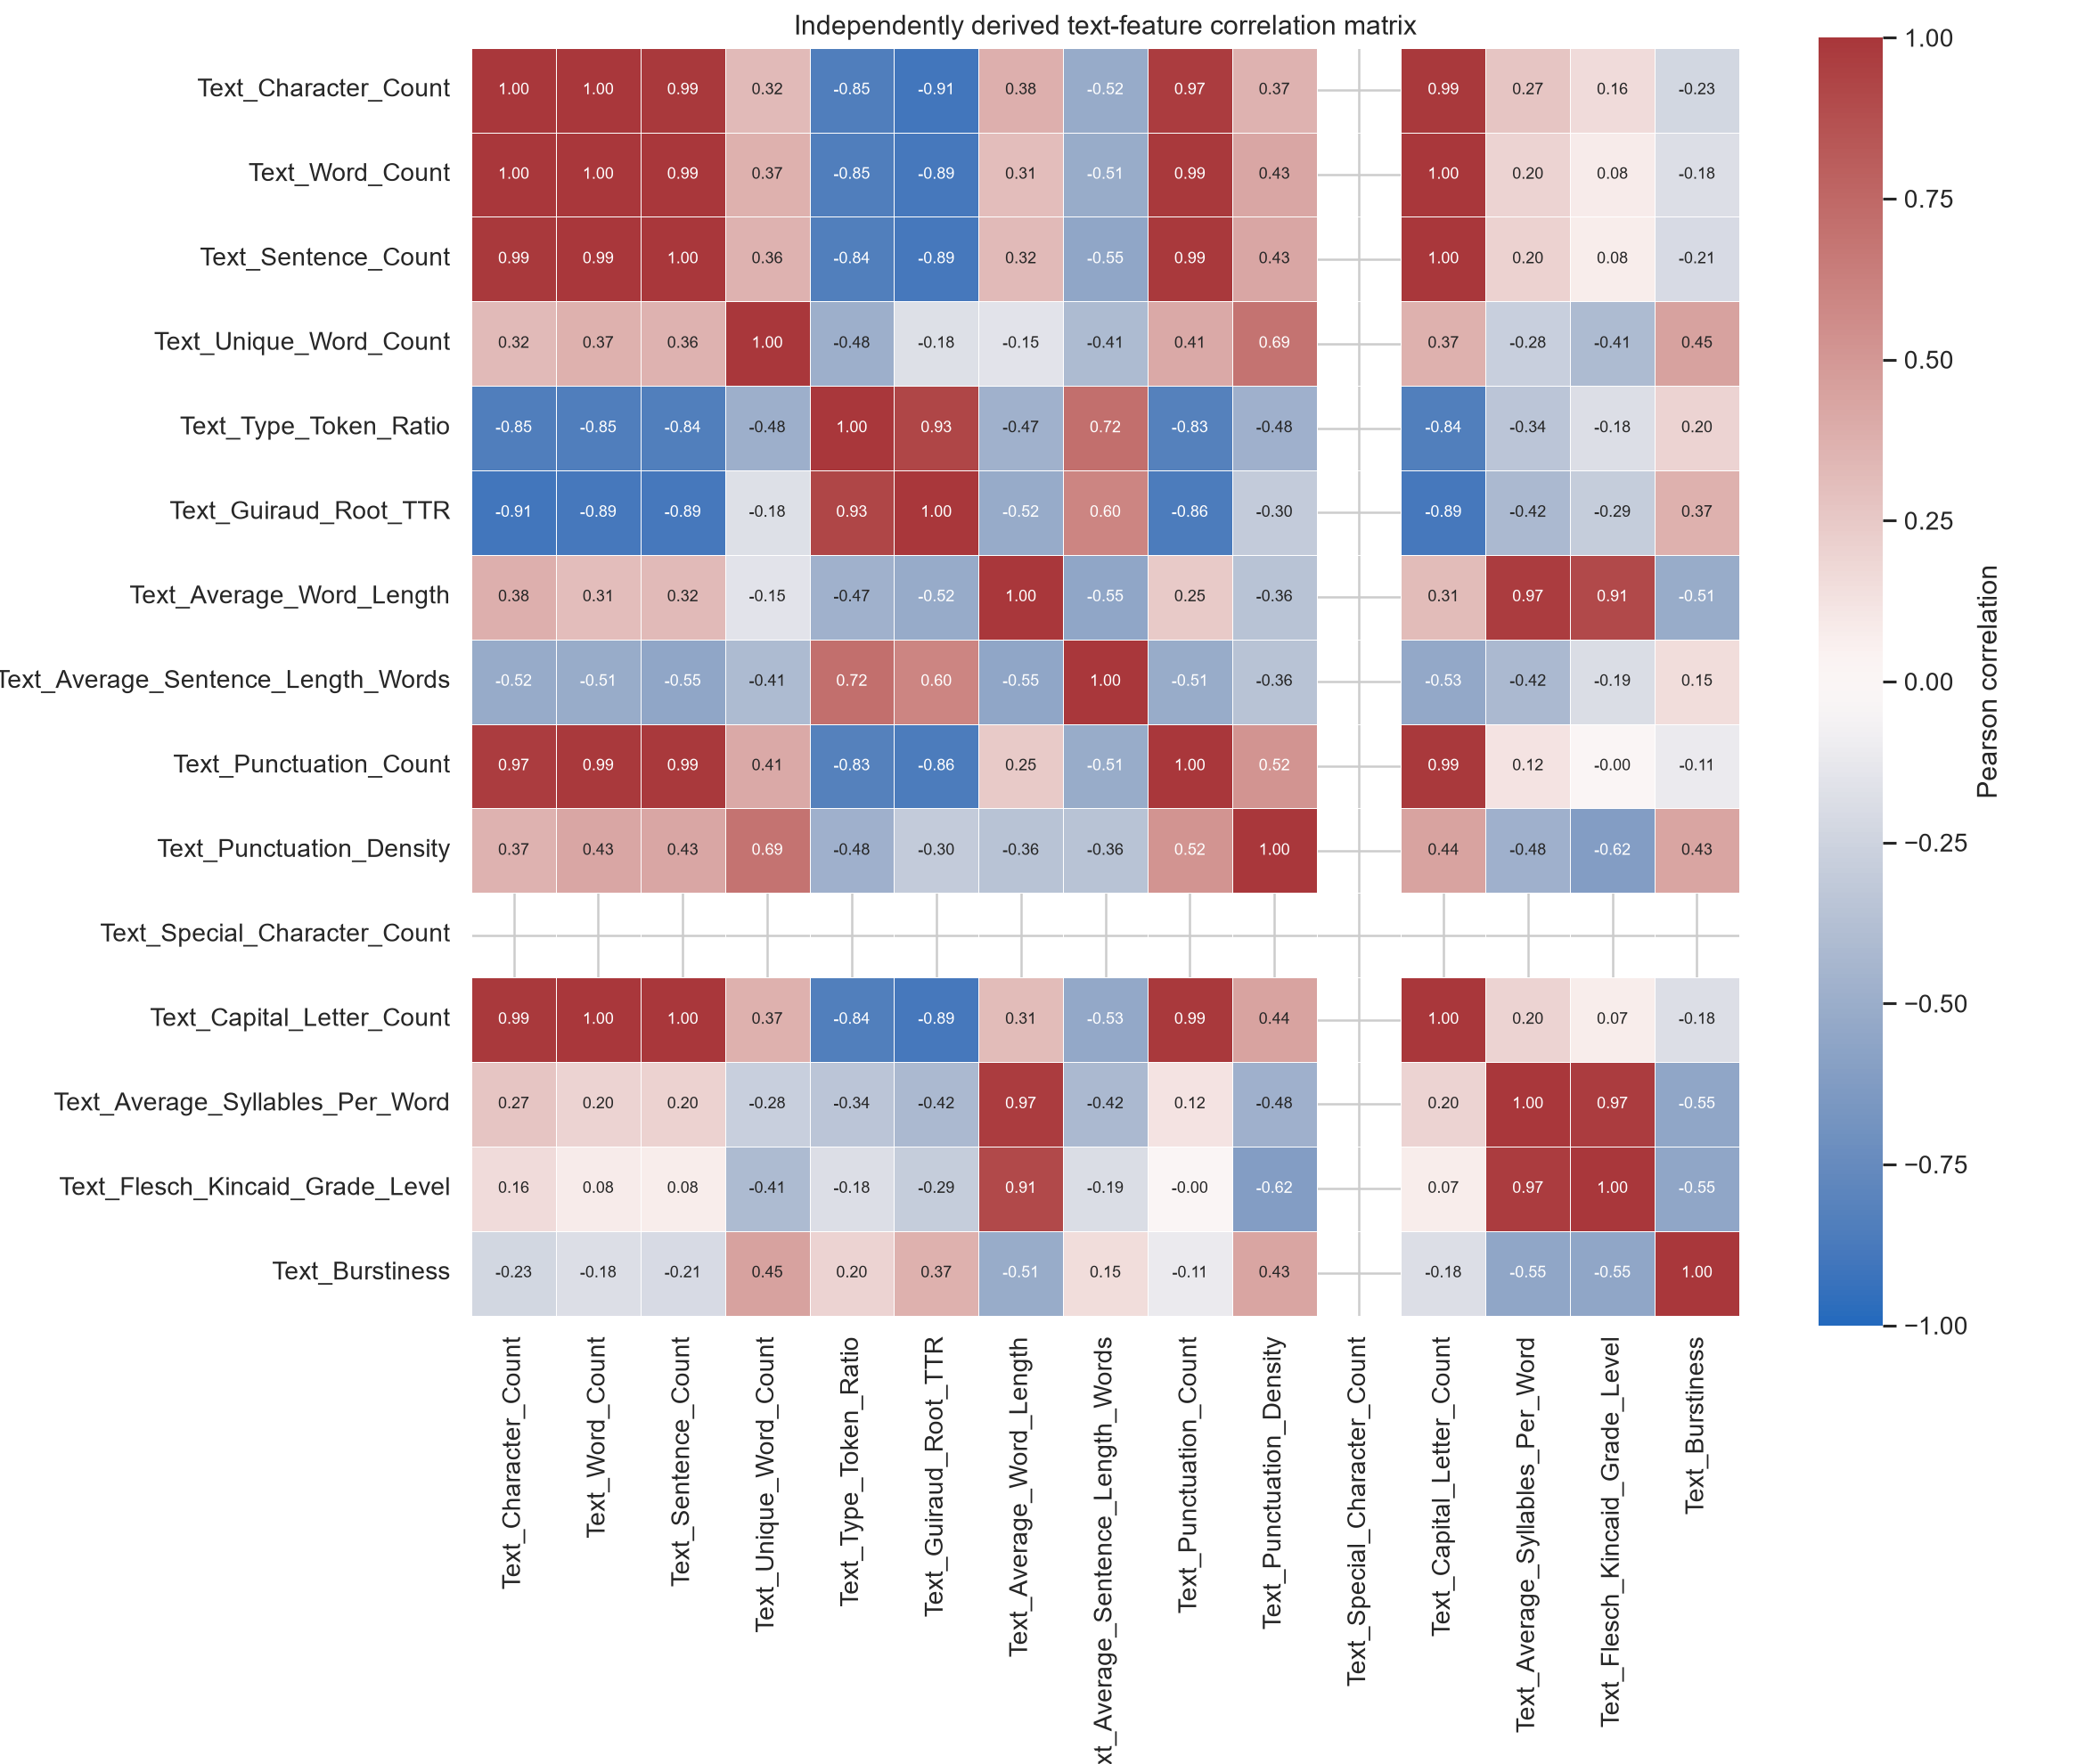

In [14]:
show("candidate_text_feature_correlation_matrix.png", 750)

In [15]:
from modeling import PROCESSED_PATH

processed = pd.read_csv(PROCESSED_PATH)
print(f"Processed rows: {len(processed):,}; columns: {list(processed.columns)}")
print("Missing values in model features:", int(processed[FINAL_FEATURE_COLUMNS].isna().sum().sum()))
processed.groupby("Label_Name")[FINAL_FEATURE_COLUMNS].median().T.round(3)

Processed rows: 50,000; columns: ['Text_ID', 'Raw_Text', 'Label', 'Label_Name', 'Text_Word_Count', 'Text_Average_Word_Length', 'Text_Average_Sentence_Length_Words', 'Text_Guiraud_Root_TTR', 'Text_Punctuation_Density', 'Text_Flesch_Kincaid_Grade_Level', 'Text_Burstiness']
Missing values in model features: 0


Label_Name,AI,Human
Text_Word_Count,246.000,251.000
Text_Average_Word_Length,6.988,6.152
Text_Average_Sentence_Length_Words,8.528,8.609
Text_Guiraud_Root_TTR,4.732,5.323
Text_Punctuation_Density,0.028,0.036
Text_Flesch_Kincaid_Grade_Level,15.800,11.317
Text_Burstiness,-0.515,-0.341


**Missing values:** none in the seven features. **Encoding:** no categorical inputs remain,
so nothing needs encoding. **Scaling:** done inside each model's pipeline and fit on
training folds only (logistic regression needs it; random forest does not).
**Outliers:** kept. These are real texts, and dropping extreme rows would change what the
model is tested on.

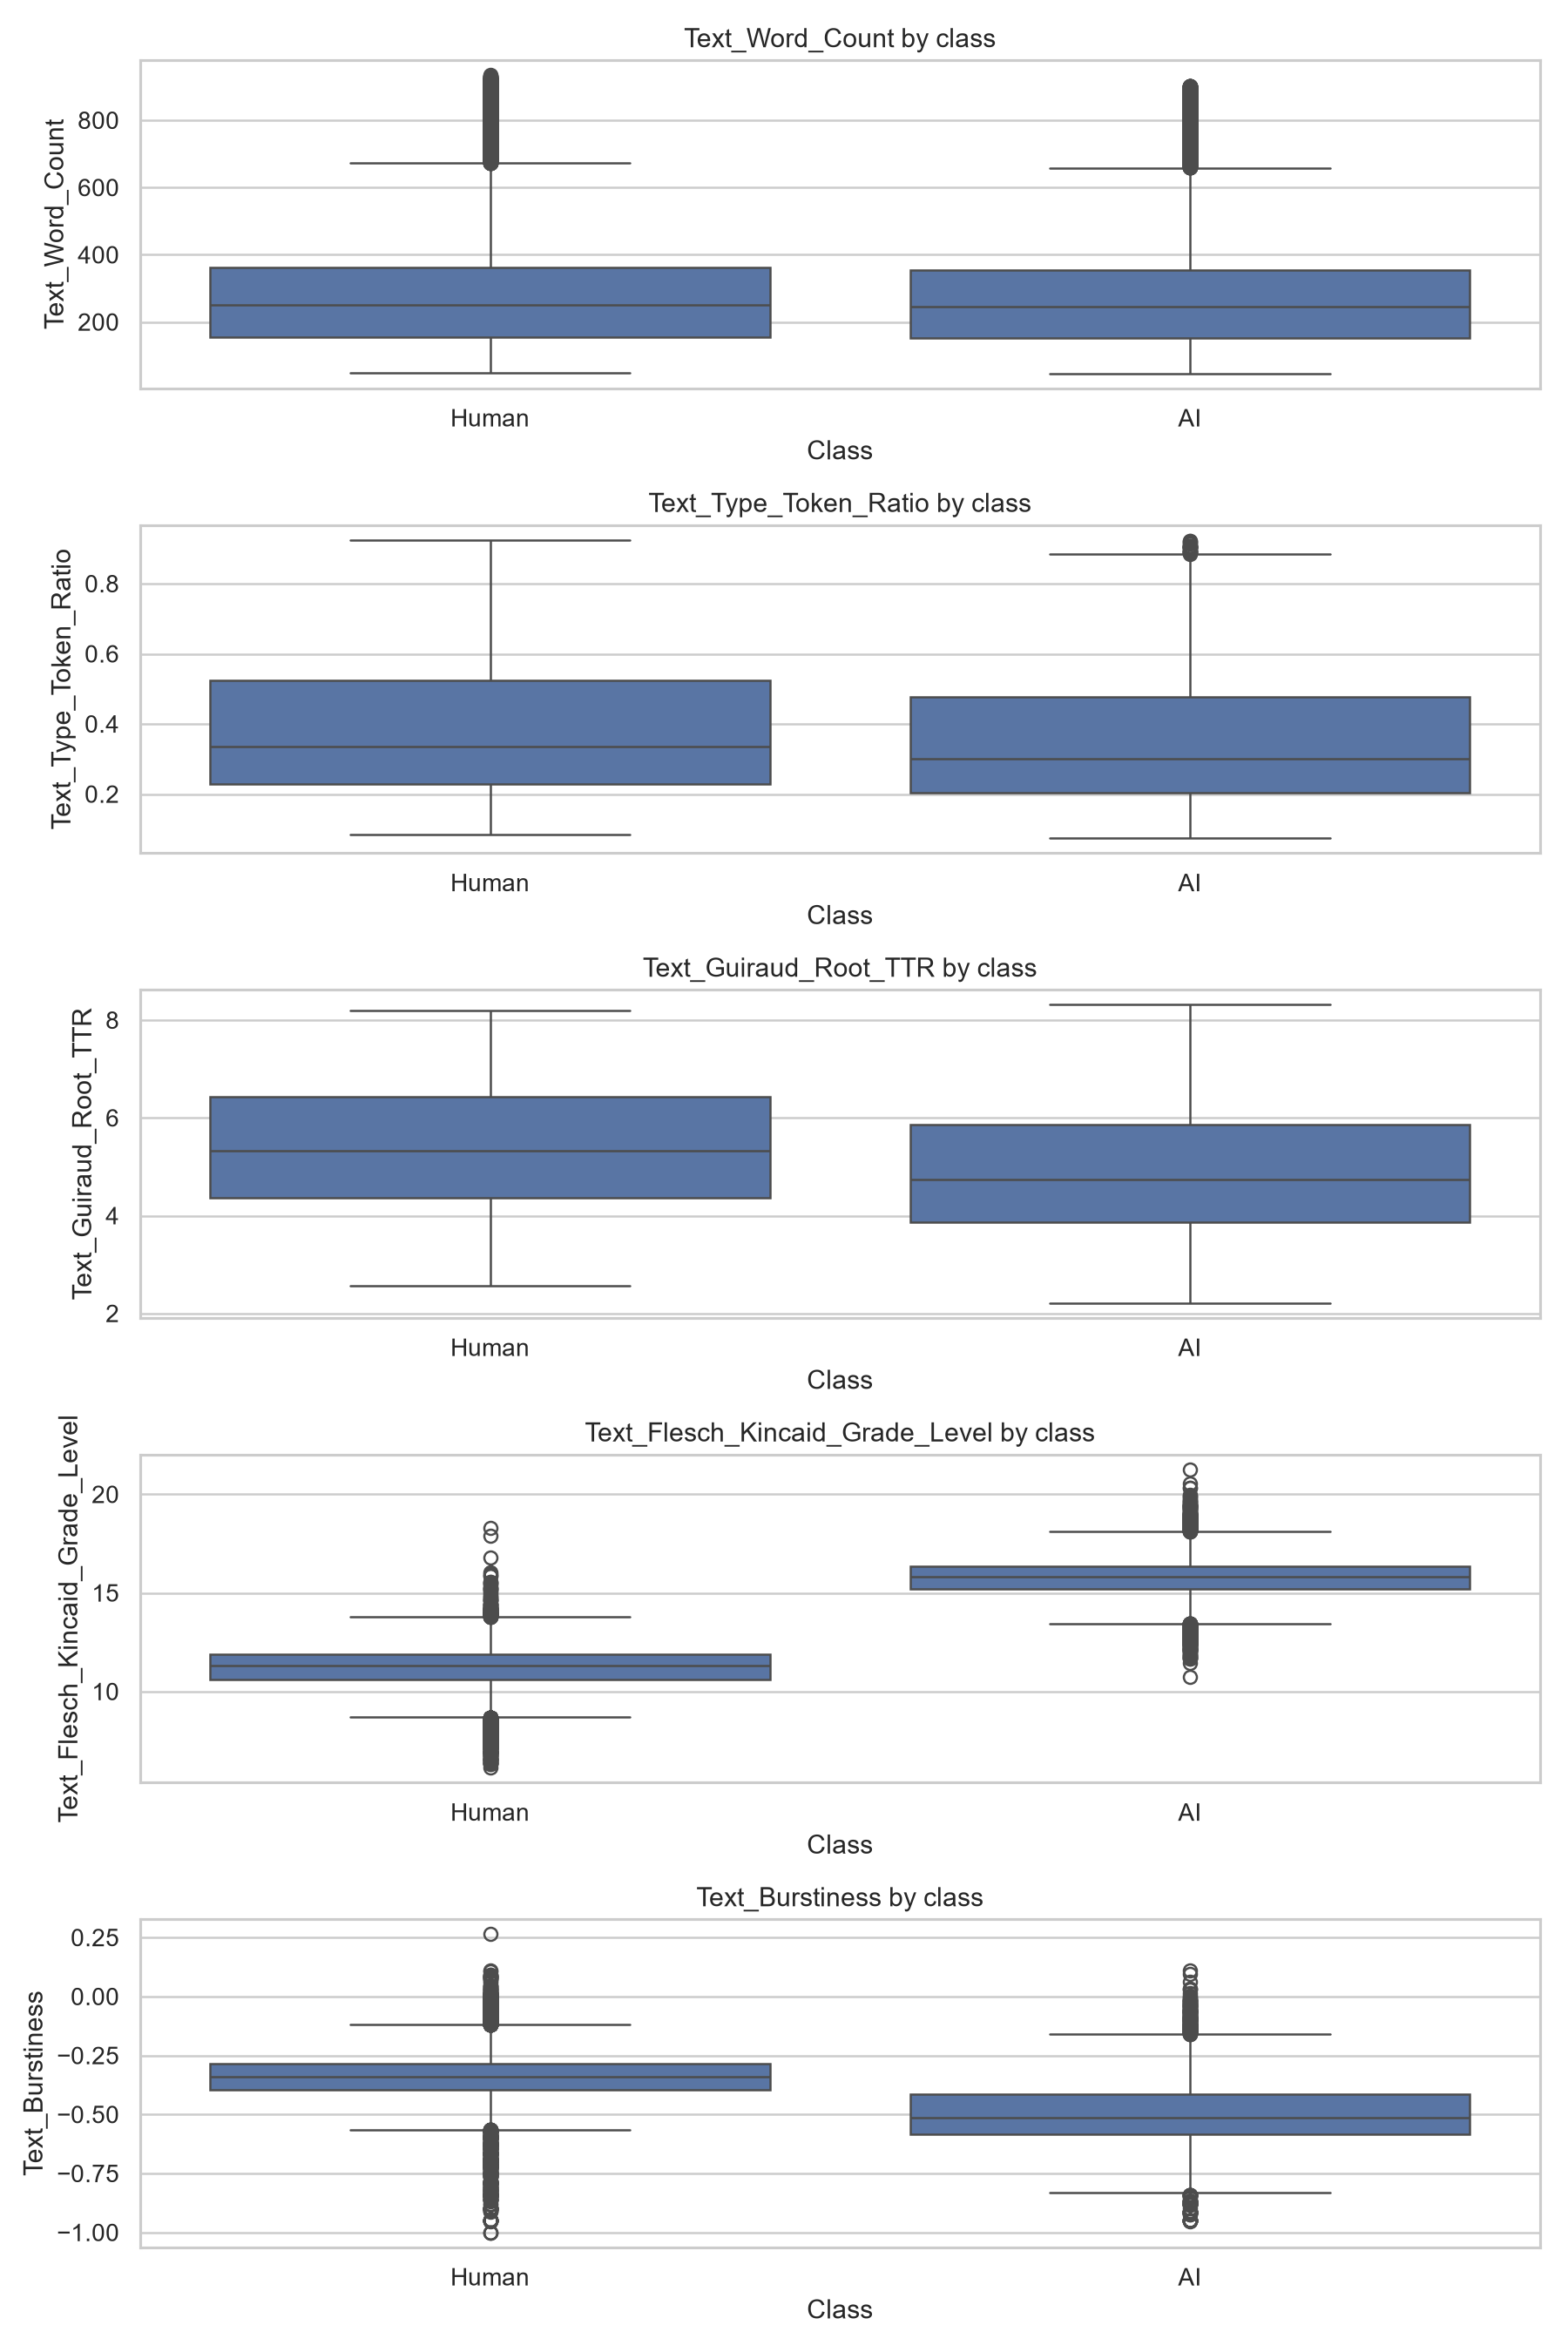

In [16]:
show("candidate_text_feature_distributions.png", 900)

### Step 3: Near-duplicates and template families

If almost the same text appeared in both training and test sets, the test score would be
too optimistic. `src/build_splits.py` compares every pair of texts by shared word
trigrams (three-word sequences) and groups:
- **near-duplicates** with similarity ≥ 0.82. These groups never cross the train/test split.
- **template families** with similarity ≥ 0.60. These are used for a harder stress test.

Both thresholds were chosen from the data. The histogram below shows how they were picked.

In [17]:
summary = json.loads((METRICS / "split_summary.json").read_text())
pd.Series({
    "rows": summary["rows"],
    "near-duplicate threshold": summary["near_dup_threshold"],
    "near-duplicate groups": summary["near_dup_groups"],
    "rows in multi-text groups": summary["near_dup_rows_in_multi_text_groups"],
    "largest group": summary["near_dup_largest_group"],
    "groups mixing Human and AI": summary["near_dup_mixed_label_groups"],
    "template families": summary["template_families"],
    "families mixing Human and AI": summary["mixed_label_families"],
    "max Human-AI pair similarity": summary["max_human_ai_pair_similarity"],
}).to_frame("value")

,value
rows,50000.00
near-duplicate threshold,0.82
near-duplicate groups,47779.00
rows in multi-text groups,3027.00
largest group,140.00
groups mixing Human and AI,0.00
template families,11.00
families mixing Human and AI,0.00
max Human-AI pair similarity,0.06


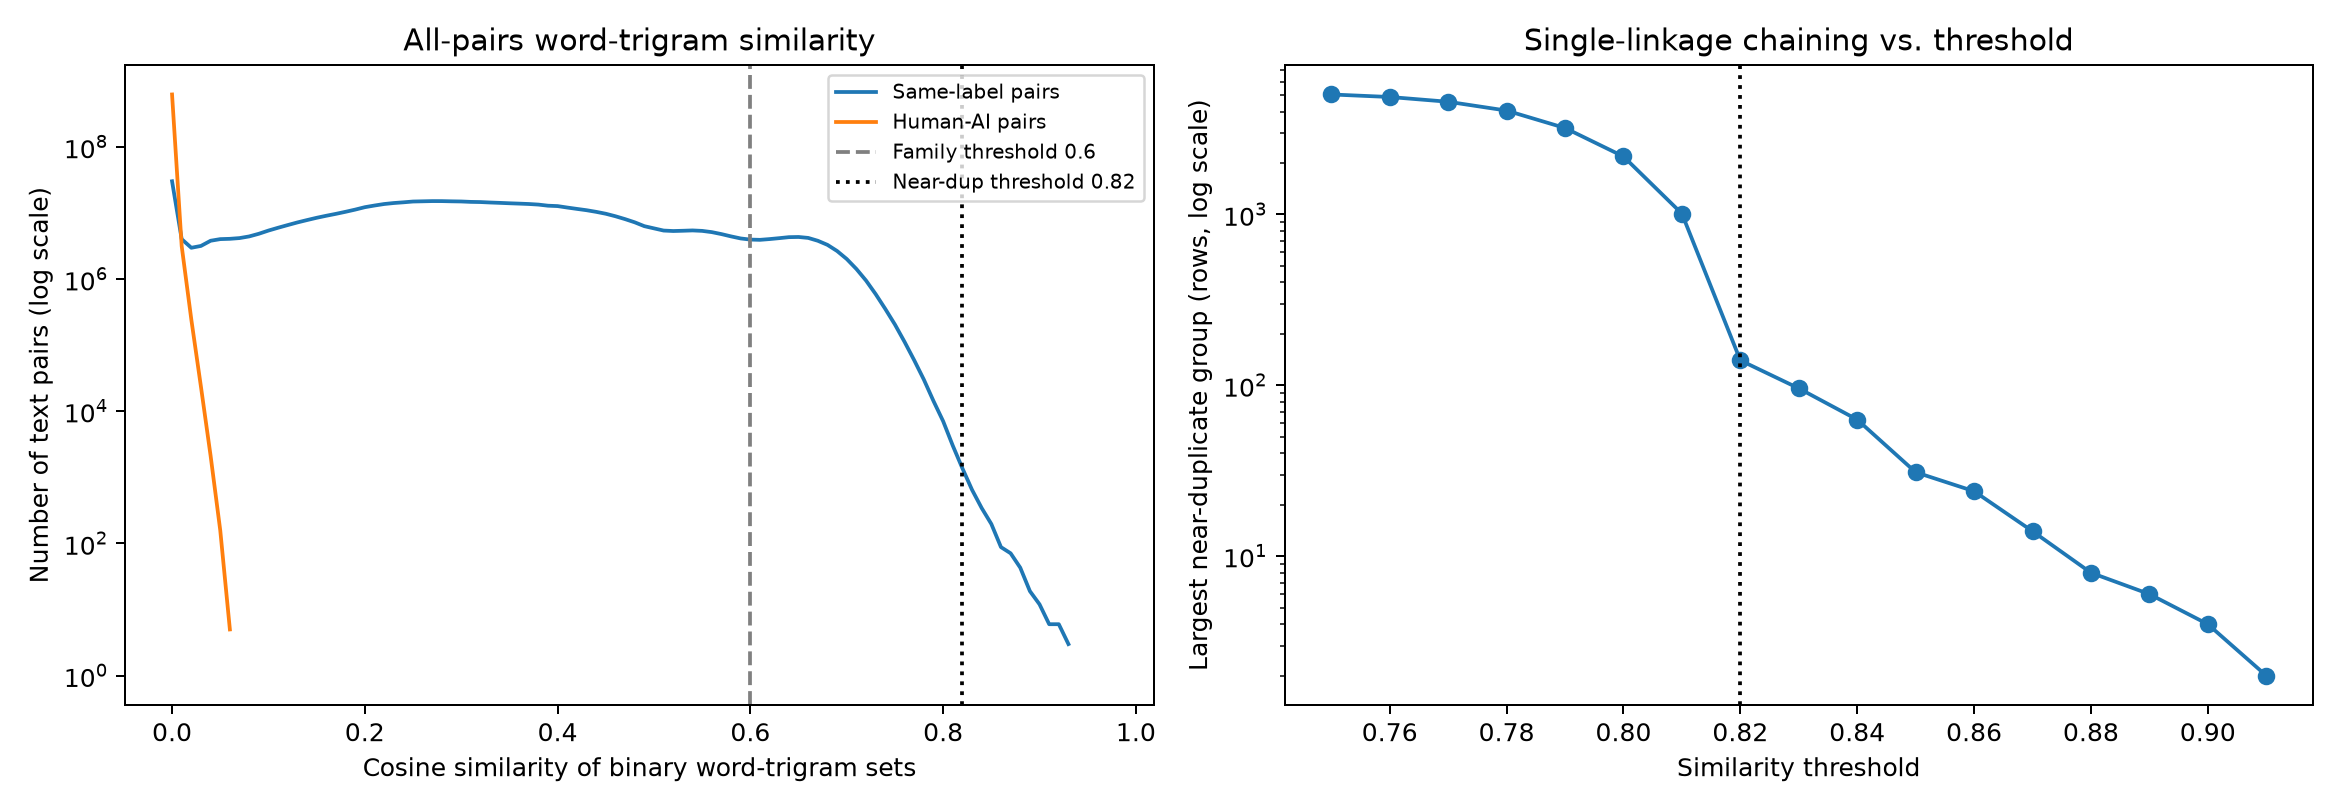

In [18]:
show("near_duplicate_similarity_diagnostics.png", 900)

**Key finding:** the 50,000 texts come from just **11 writing templates** (6 Human, 5 AI).
Every template belongs to one class. A model can score very high by recognizing the
template rather than human vs. AI writing in general. This is the main limitation of
the dataset.

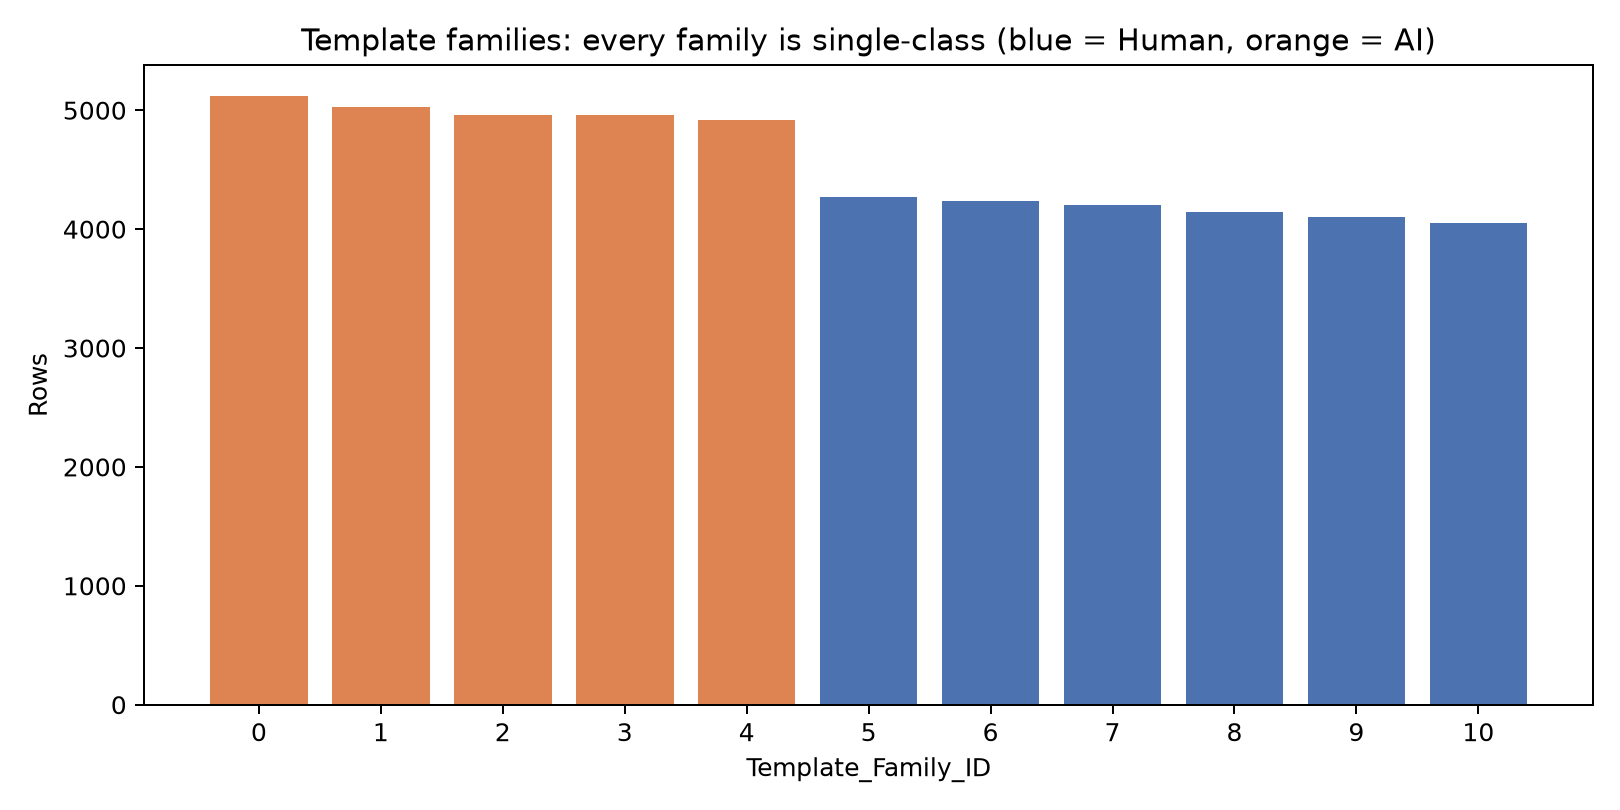

In [19]:
show("template_families_by_class.png", 750)

### Step 4: Train/test split and cross-validation folds

In [20]:
from modeling import SPLITS_PATH

splits = pd.read_csv(SPLITS_PATH)
split_table = splits.groupby("Split").agg(rows=("Label", "size"), ai_share=("Label", "mean"))
split_table["ai_share"] = split_table["ai_share"].round(4)
split_table

,rows,ai_share
Split,,
test,10000,0.5
train,40000,0.5


In [21]:
train_rows = splits[splits["Split"] == "train"]
fold_table = train_rows.groupby("CV_Fold").agg(rows=("Label", "size"), ai_share=("Label", "mean")).round(4)
fold_table

,rows,ai_share
CV_Fold,,
0,8000,0.5
1,8000,0.5
2,8000,0.5
3,8000,0.5
4,8000,0.5


In [22]:
# Leakage check: no near-duplicate group appears in both partitions.
groups_per_split = splits.groupby("NearDup_Group_ID")["Split"].nunique()
print("Near-duplicate groups crossing train/test:", int((groups_per_split > 1).sum()))

Near-duplicate groups crossing train/test: 0


- **80/20 split**, stratified by label and grouped by near-duplicate group, with seed 478.
- **5 cross-validation folds** inside the training set, built the same way. Every model is
  tuned on these same folds.
- The test set is used **once per model**, after tuning is finished.

## Part 3. Model development

**Rubric section:** Model Development (20 pts), with each model's own evaluation.

Both models use the same seven features, the same group-aware train/test split, the same five CV
folds, and the same selection metric (ROC-AUC). Set `RETRAIN = True` in the setup cell to retrain
them here.

### Model 1: Logistic regression

**Why this model.** It's the simplest reasonable baseline: a linear boundary on seven
features. Its coefficients show directly which text properties push toward AI or Human.
Any more complex model has to beat it to justify the extra complexity.

**Assumptions.** The log-odds of AI is a linear function of the standardized features.
Rows are independent, which is why near-duplicates stay on one side of every split.
The model is scale-sensitive, so a `StandardScaler` is fit inside the pipeline on training folds only.

**Hyperparameters tuned** (16 combinations × 5 group-aware folds, chosen by ROC-AUC):

| Hyperparameter | Values | Meaning |
| --- | --- | --- |
| `C` | 1e-4 … 1e3 (8 values) | inverse regularization strength |
| `l1_ratio` | 0 (L2), 1 (L1) | L1 can set a weight to exactly zero |

#### Train and evaluate

With `RETRAIN = True`, this runs `src/train_logistic_regression.py` from scratch: it tunes on the training folds, evaluates once on the test set, and saves metrics and figures. With `False` it loads the saved results.

In [23]:
import train_logistic_regression

if RETRAIN or not (METRICS / "logistic_regression_metrics.json").exists():
    train_logistic_regression.main()

In [24]:
MODEL = "logistic_regression"
results = json.loads((METRICS / f"{MODEL}_metrics.json").read_text())
print("Selected hyperparameters:", results["best_params"])

Selected hyperparameters: {'clf__C': 0.1, 'clf__l1_ratio': 1.0}


#### Tuning: training vs. validation score

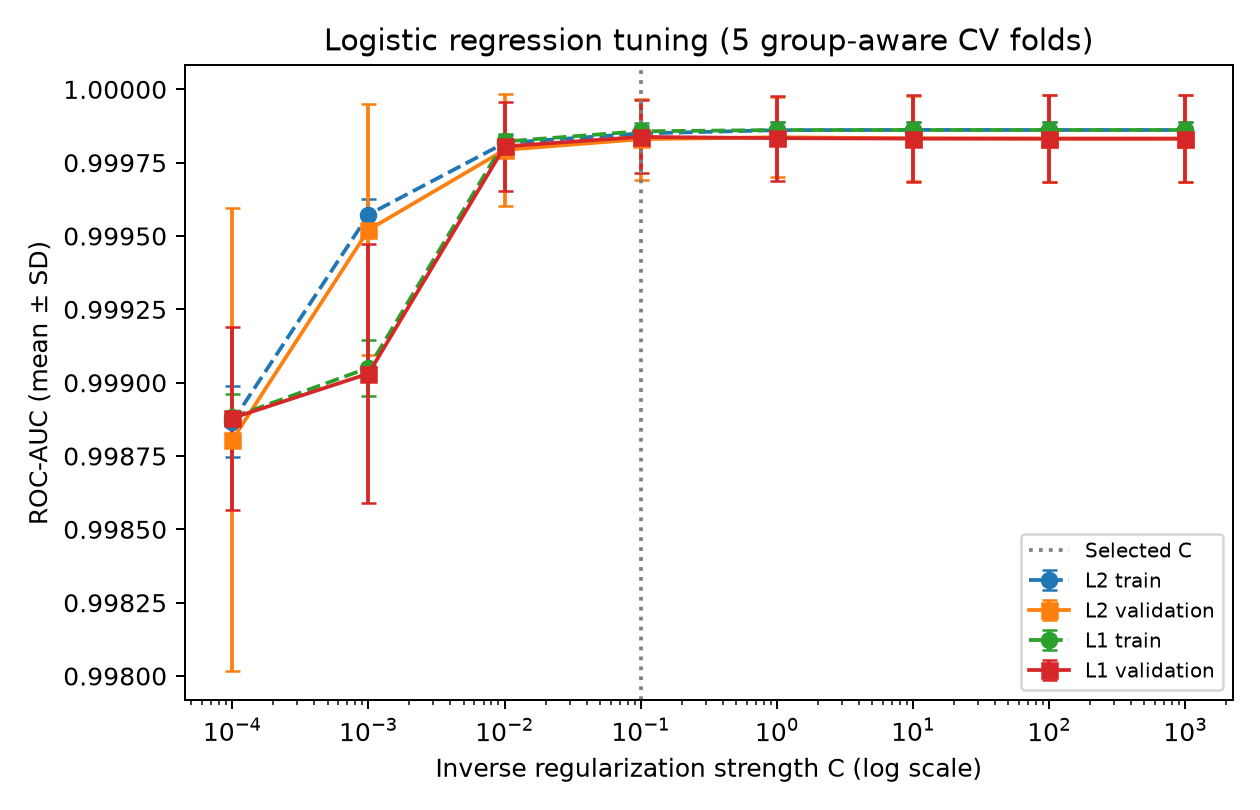

In [25]:
show("logistic_regression_tuning_curve.png", 900)

#### Training vs. validation vs. test

In [26]:
def stage_row(block, part=None):
    return {m: (block[part][m]["mean"] if part else block[m]) for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}

stages = pd.DataFrame({
    "CV train (mean)": stage_row(results["cv_near_duplicate_groups"], "train"),
    "CV validation (mean)": stage_row(results["cv_near_duplicate_groups"], "validation"),
    "Full training set": stage_row(results["full_train_metrics"]),
    "Held-out test": stage_row(results["test_metrics"]),
    "Unseen template families": stage_row(results["template_family_holdout"]["summary"], "validation"),
}).T.round(4)
stages

,accuracy,precision,recall,f1,roc_auc
CV train (mean),0.9954,0.9955,0.9952,0.9953,0.9999
CV validation (mean),0.9951,0.9951,0.9952,0.9951,0.9998
Full training set,0.9953,0.9954,0.9952,0.9953,0.9999
Held-out test,0.9944,0.9932,0.9956,0.9944,0.9998
Unseen template families,0.9888,0.9908,0.9836,0.9869,0.9984


#### Test-set confusion matrix and ROC curve

In [27]:
pd.Series(results["test_confusion_matrix"]).to_frame("rows")

,rows
true_human_pred_human,4966
true_human_pred_ai,34
true_ai_pred_human,22
true_ai_pred_ai,4978


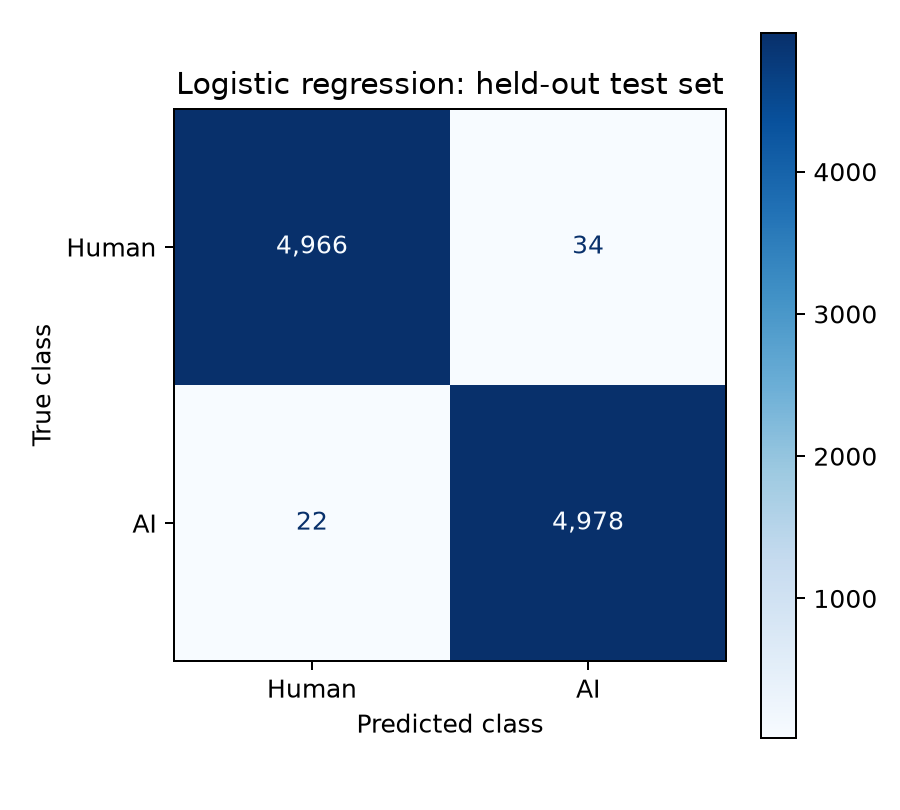

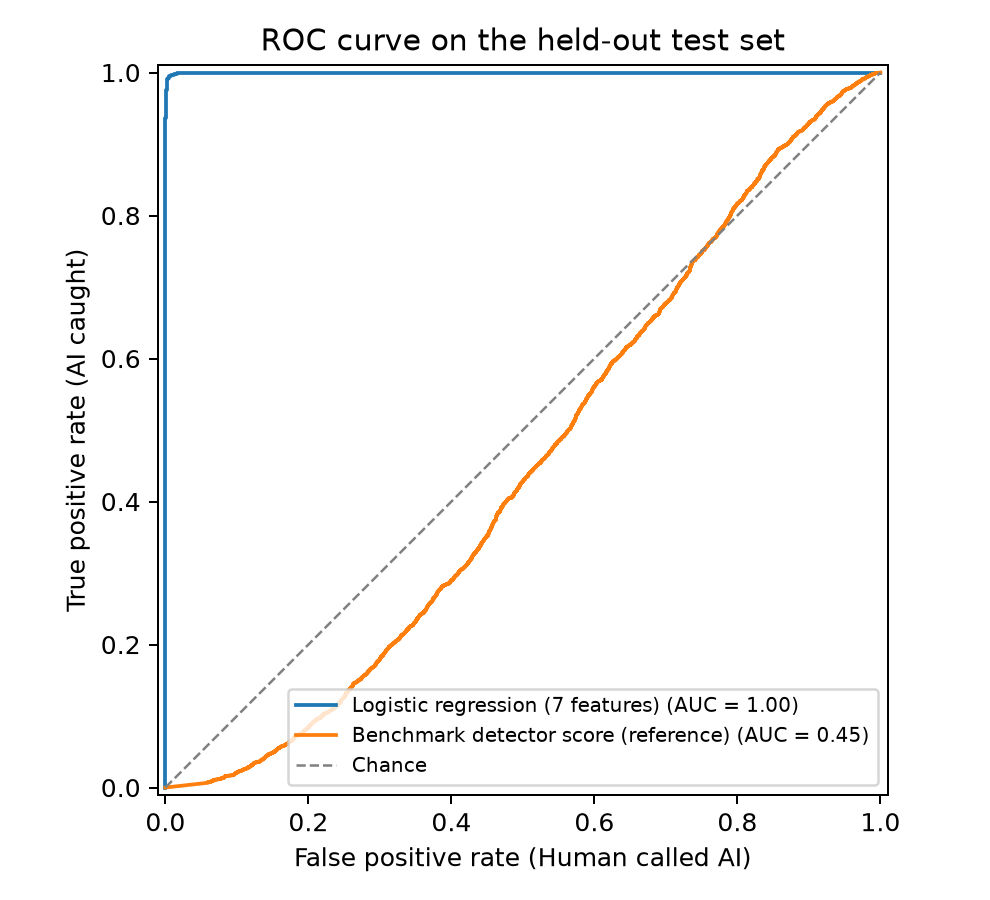

In [28]:
show("logistic_regression_confusion_matrix.png", 450)
show("logistic_regression_roc_curve.png", 500)

#### Interpretation: standardized coefficients

In [29]:
pd.Series(results["standardized_coefficients"]).sort_values().round(3).to_frame("coefficient (log-odds per 1 SD)")

,coefficient (log-odds per 1 SD)
Text_Punctuation_Density,-3.988
Text_Word_Count,-0.879
Text_Burstiness,-0.143
Text_Guiraud_Root_TTR,0.000
Text_Average_Sentence_Length_Words,0.099
Text_Flesch_Kincaid_Grade_Level,3.602
Text_Average_Word_Length,6.618


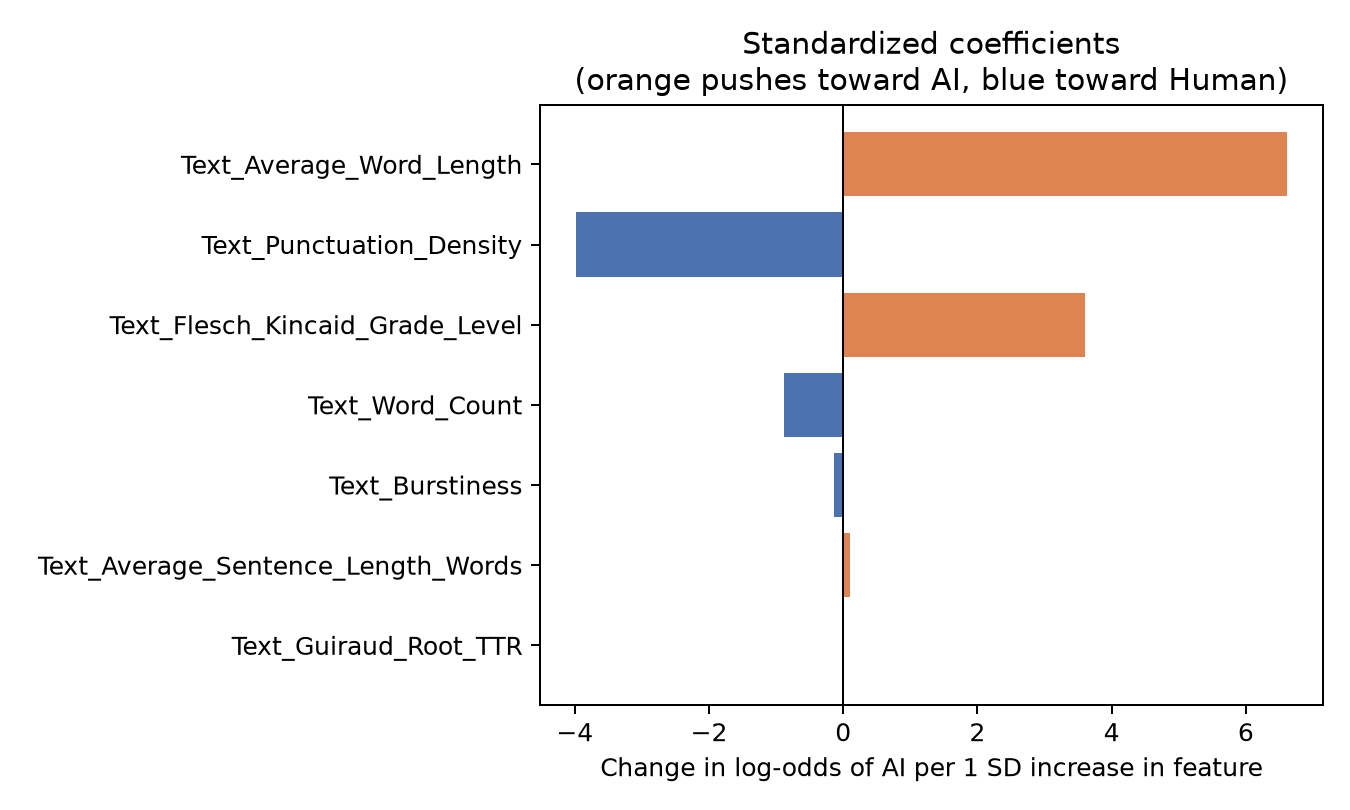

In [30]:
show("logistic_regression_coefficients.png", 700)

Longer words and a higher reading grade push toward **AI**. More punctuation and longer
texts push toward **Human**. The L1 penalty set vocabulary variety (`Guiraud_Root_TTR`)
to exactly zero, so it adds nothing once the other six features are known.

**Over/underfitting:** training and validation scores are nearly identical (about 99.5%),
so there's no sign of overfitting. The drop on unseen templates (about 98.9%) is the
real generalization gap.

#### Stress test: unseen templates

Each fold below holds out whole template families, so the model is scored on writing
styles it never saw during training. This uses the training partition only.

In [31]:
family = results["template_family_holdout"]
pd.DataFrame([
    {**fold, "validation_accuracy": acc}
    for fold, acc in zip(family["folds"], family["summary"]["validation"]["accuracy"]["folds"])
])

,validation_families,validation_rows,validation_ai_proportion,validation_accuracy
0,"[0, 9, 10]",10506,0.390158,0.965448
1,"[1, 8]",7390,0.546414,1.000000
2,"[2, 6]",7407,0.540570,1.000000
3,"[4, 7]",7340,0.536104,0.980381
4,"[3, 5]",7357,0.533370,0.998097


#### External reference

The benchmark's own detector score, thresholded at 50, on the same test rows. It is
evaluation-only and never a model input.

In [32]:
pd.Series(results["benchmark_detector_reference_on_test"]).to_frame("value")

,value
note,"Detection_Score_Benchmark_Model_A, thresholded at 50; evaluation only"
accuracy,0.487
precision,0.490154
recall,0.6472
f1,0.557835
roc_auc,0.448033


### Model 2: Random forest

**Why this model.** It's a nonlinear contrast to logistic regression. Trees can learn
thresholds and interactions between features (for example, "long words *and* low
punctuation") that a linear model can't. It needs no scaling and gives feature importances.

**Characteristics.** It averages many decision trees, each trained on a bootstrap sample
and choosing among a random subset of features at each split. Averaging reduces the
variance that a single deep tree would have. Its main risk is memorizing the training
data, so we compare training and validation scores closely.

**Hyperparameters tuned** (36 combinations × the same 5 group-aware folds, chosen by ROC-AUC):

| Hyperparameter | Values | Meaning |
| --- | --- | --- |
| `max_depth` | 4, 8, 16, None | how deep each tree can grow |
| `min_samples_leaf` | 1, 10, 50 | minimum texts in a leaf; larger means a smoother model |
| `max_features` | 2, 4, 7 | features tried at each split; 7 means plain bagging |

`n_estimators` is fixed at 300. More trees reduce variance but don't cause
overfitting, so this is a compute choice rather than a tuning choice.
`class_weight=None`, because the classes are balanced.

**Run time:** about 3 minutes on a 14-core laptop.

#### Train and evaluate

With `RETRAIN = True`, this runs `src/train_random_forest.py` from scratch: it tunes on the training folds, evaluates once on the test set, and saves metrics and figures. With `False` it loads the saved results.

In [33]:
import train_random_forest

if RETRAIN or not (METRICS / "random_forest_metrics.json").exists():
    train_random_forest.main()

In [34]:
MODEL = "random_forest"
results = json.loads((METRICS / f"{MODEL}_metrics.json").read_text())
print("Selected hyperparameters:", results["best_params"])

Selected hyperparameters: {'clf__max_depth': 'None', 'clf__max_features': 2, 'clf__min_samples_leaf': 1}


#### Tuning: training vs. validation score

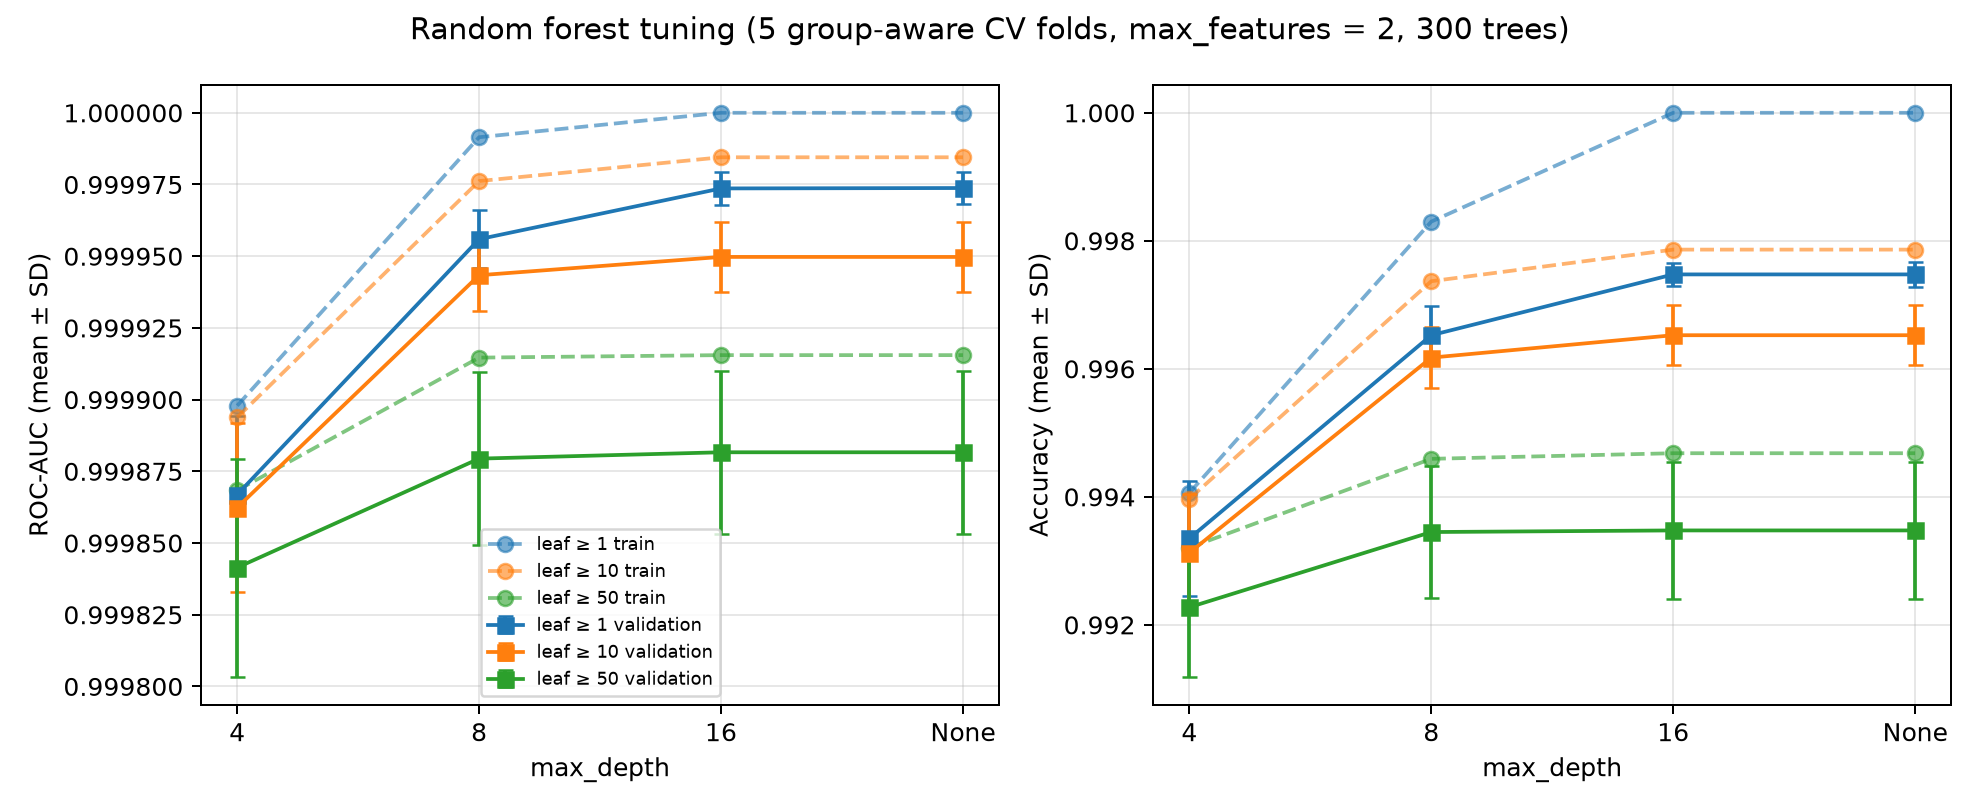

In [35]:
show("random_forest_tuning_curve.png", 900)

#### Training vs. validation vs. test

In [36]:
def stage_row(block, part=None):
    return {m: (block[part][m]["mean"] if part else block[m]) for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]}

stages = pd.DataFrame({
    "CV train (mean)": stage_row(results["cv_near_duplicate_groups"], "train"),
    "CV validation (mean)": stage_row(results["cv_near_duplicate_groups"], "validation"),
    "Full training set": stage_row(results["full_train_metrics"]),
    "Held-out test": stage_row(results["test_metrics"]),
    "Unseen template families": stage_row(results["template_family_holdout"]["summary"], "validation"),
}).T.round(4)
stages

,accuracy,precision,recall,f1,roc_auc
CV train (mean),1.0000,1.0000,1.0000,1.0000,1.0000
CV validation (mean),0.9975,0.9974,0.9976,0.9975,1.0000
Full training set,1.0000,1.0000,1.0000,1.0000,1.0000
Held-out test,0.9952,0.9926,0.9978,0.9952,0.9999
Unseen template families,0.9859,0.9886,0.9794,0.9837,0.9984


#### Test-set confusion matrix and ROC curve

In [37]:
pd.Series(results["test_confusion_matrix"]).to_frame("rows")

,rows
true_human_pred_human,4963
true_human_pred_ai,37
true_ai_pred_human,11
true_ai_pred_ai,4989


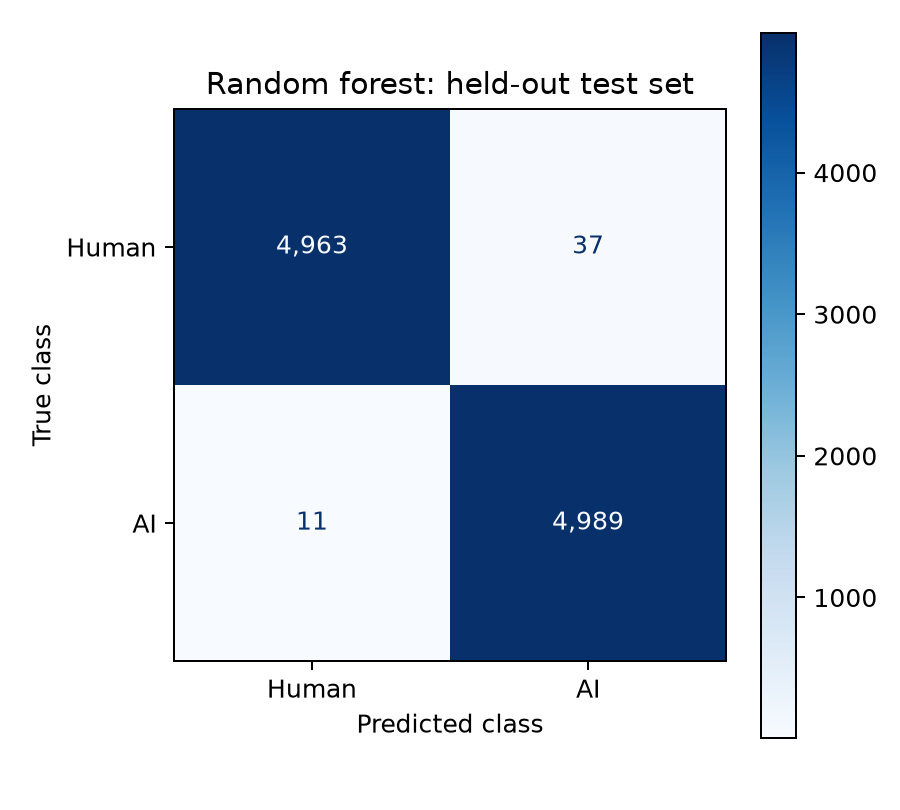

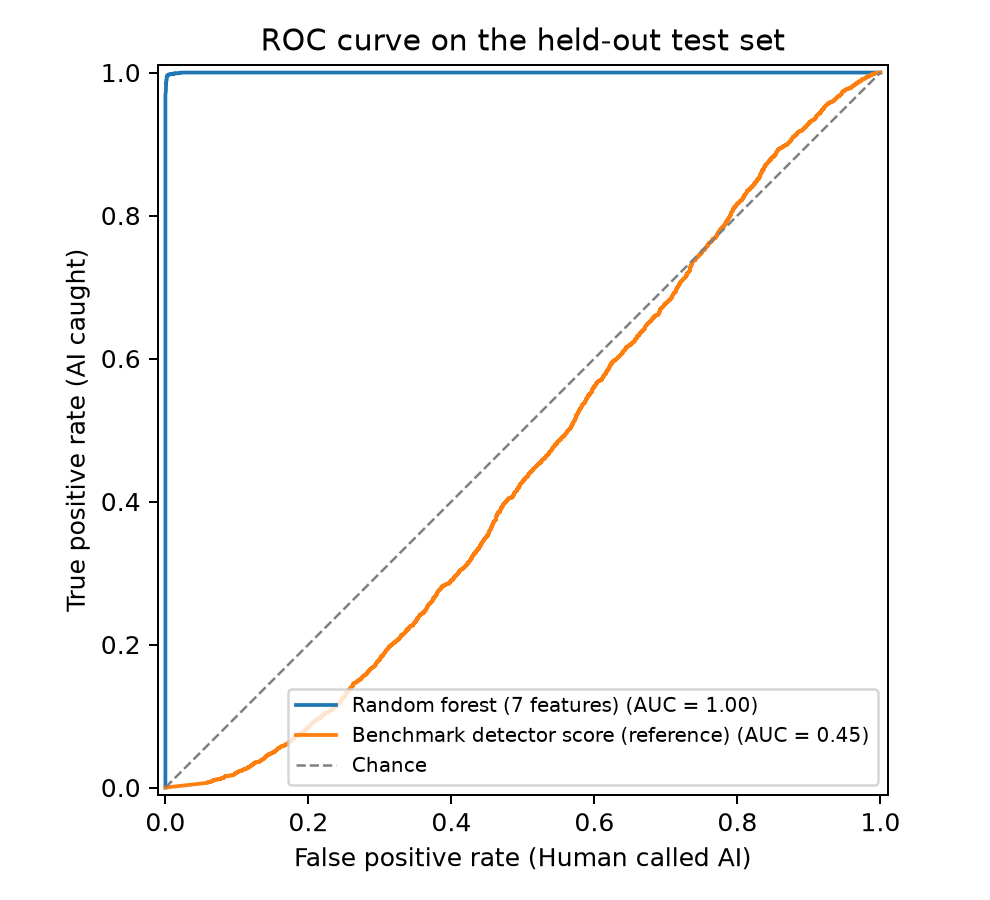

In [38]:
show("random_forest_confusion_matrix.png", 450)
show("random_forest_roc_curve.png", 500)

#### Interpretation: feature importance

In [39]:
pd.DataFrame(results["feature_importance"]).T.sort_values("permutation_mean", ascending=False).round(4)

,permutation_mean,permutation_std,impurity
Text_Flesch_Kincaid_Grade_Level,0.1676,0.0028,0.4008
Text_Average_Word_Length,0.0133,0.0005,0.2892
Text_Punctuation_Density,0.0055,0.0002,0.2048
Text_Word_Count,0.0002,0.0000,0.0076
Text_Average_Sentence_Length_Words,0.0001,0.0000,0.0203
Text_Burstiness,0.0001,0.0000,0.0648
Text_Guiraud_Root_TTR,0.0001,0.0000,0.0126


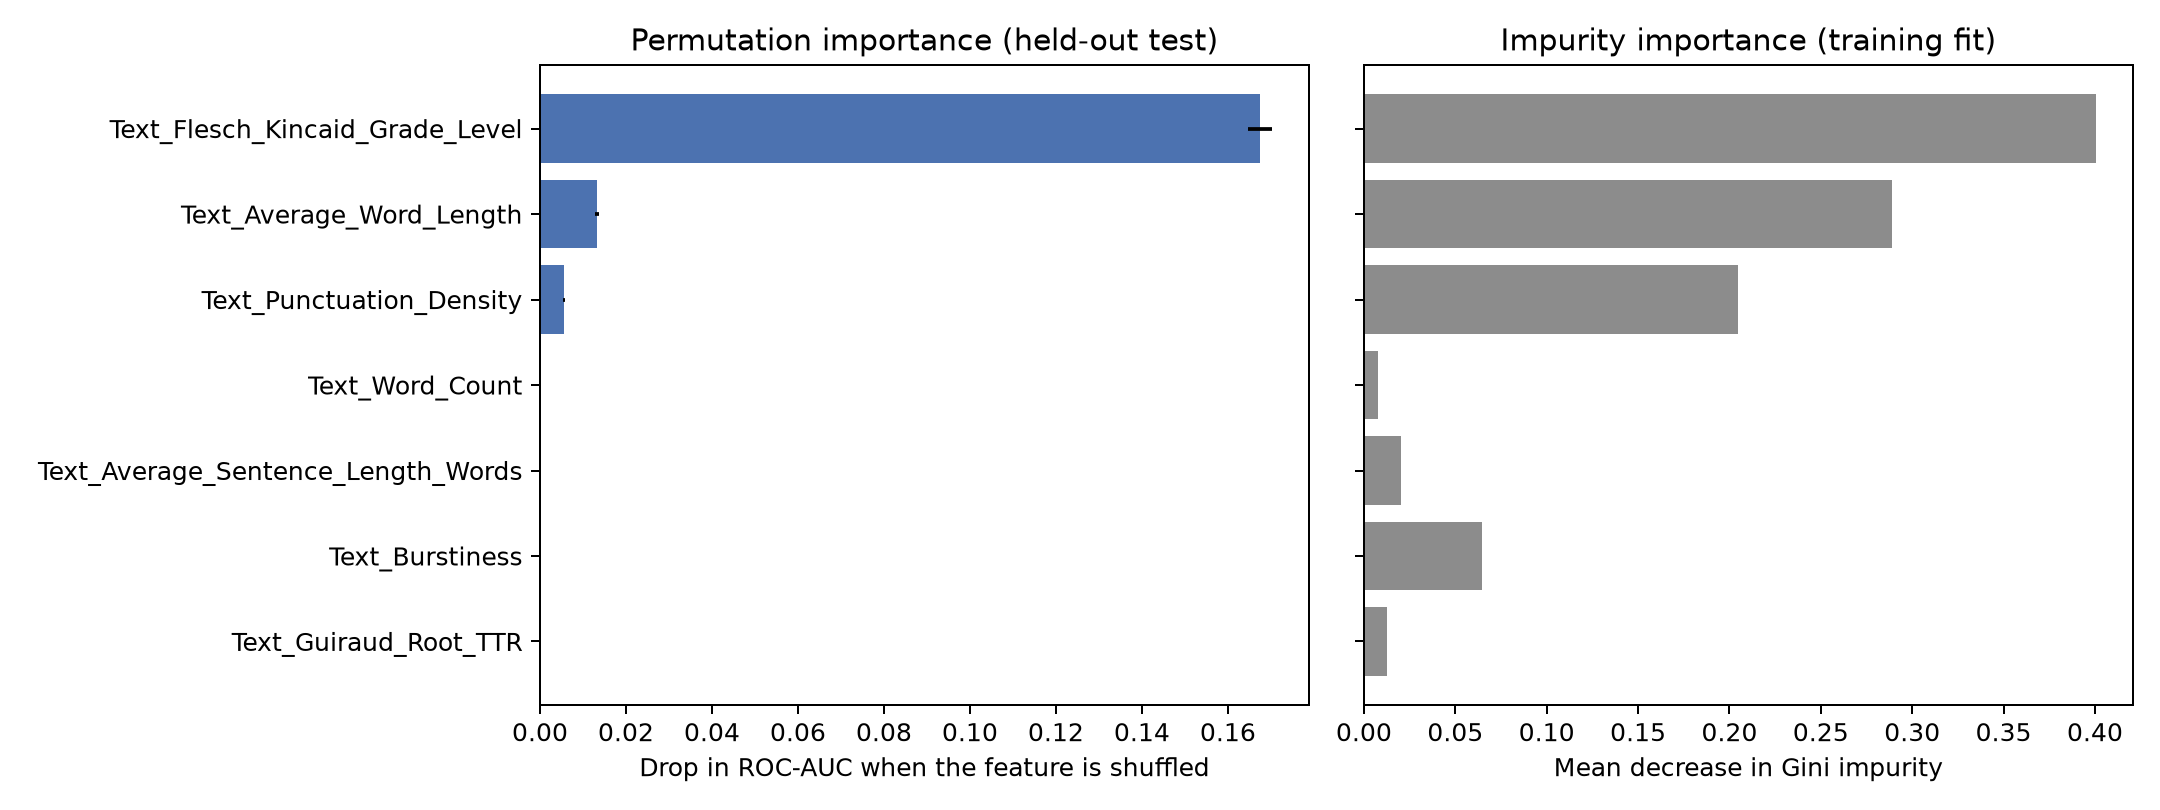

In [40]:
show("random_forest_feature_importance.png", 900)

**Permutation importance** shuffles one feature on the test set and measures how much
ROC-AUC drops. It is measured on held-out data, so it is the more trustworthy view.
Reading grade level dominates, followed by average word length and punctuation density.
These are the same features logistic regression weighted most.
**Impurity importance** is computed on training data and spreads credit across
correlated features, so it overstates features like burstiness.

**Over/underfitting:** the selected forest uses fully grown trees and fits the training
data perfectly (100%), while validation accuracy is 99.75%. That gap is small and typical
for random forests. Validation accuracy still rises with depth, so the extra fit isn't
hurting results on near-duplicate-safe folds. On **unseen templates**, though, the forest
does slightly worse than logistic regression (see notebook 05).

#### Stress test: unseen templates

Each fold below holds out whole template families, so the model is scored on writing
styles it never saw during training. This uses the training partition only.

In [41]:
family = results["template_family_holdout"]
pd.DataFrame([
    {**fold, "validation_accuracy": acc}
    for fold, acc in zip(family["folds"], family["summary"]["validation"]["accuracy"]["folds"])
])

,validation_families,validation_rows,validation_ai_proportion,validation_accuracy
0,"[0, 9, 10]",10506,0.390158,0.959737
1,"[1, 8]",7390,0.546414,1.000000
2,"[2, 6]",7407,0.540570,1.000000
3,"[4, 7]",7340,0.536104,0.971662
4,"[3, 5]",7357,0.533370,0.998097


#### External reference

The benchmark's own detector score, thresholded at 50, on the same test rows. It is
evaluation-only and never a model input.

In [42]:
pd.Series(results["benchmark_detector_reference_on_test"]).to_frame("value")

,value
note,"Detection_Score_Benchmark_Model_A, thresholded at 50; evaluation only"
accuracy,0.487
precision,0.490154
recall,0.6472
f1,0.557835
roc_auc,0.448033


## Part 4. Model evaluation, comparison and recommendation

**Rubric section:** Model Evaluation and Comparison (20 pts).

Both models used the same seven features, the same train/test split, the same five group-aware CV
folds, the same selection metric (ROC-AUC), and the same stress test. That makes this comparison
fair. `src/compare_models.py` reads each model's saved results. Nothing is retrained here.

In [43]:
import compare_models

compare_models.main()

              Model                    Stage  accuracy  precision  recall     f1  roc_auc
Logistic regression                 CV train    0.9954     0.9955  0.9952 0.9953   0.9999
Logistic regression            CV validation    0.9951     0.9951  0.9952 0.9951   0.9998
Logistic regression            Held-out test    0.9944     0.9932  0.9956 0.9944   0.9998
Logistic regression Template-family hold-out    0.9888     0.9908  0.9836 0.9869   0.9984
      Random forest                 CV train    1.0000     1.0000  1.0000 1.0000   1.0000
      Random forest            CV validation    0.9975     0.9974  0.9976 0.9975   1.0000
      Random forest            Held-out test    0.9952     0.9926  0.9978 0.9952   0.9999
      Random forest Template-family hold-out    0.9859     0.9886  0.9794 0.9837   0.9984

logistic_regression_vs_random_forest: {'test_rows': 10000, 'logistic_regression_errors': 56, 'random_forest_errors': 48, 'both_wrong': 32, 'only_logistic_regression_wrong': 24, 'only_random

### Metric choice

- **Accuracy** works because the classes are exactly balanced.
- **Precision** (of texts called AI, how many really are AI) and **recall** (of AI texts,
  how many we catch) matter separately. Wrongly accusing a human writer is a costly mistake.
- **F1** balances precision and recall.
- **ROC-AUC** measures ranking quality at every threshold, not just 0.5.
- **Confusion matrices** show which kind of error each model makes.

In [44]:
table = pd.read_csv(METRICS / "model_comparison.csv")
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
table.pivot(index="Stage", columns="Model", values=metrics).round(4).reindex(
    ["CV train", "CV validation", "Held-out test", "Template-family hold-out"]
)

accuracy                         precision                            recall                \
Model                    Logistic regression Random forest Logistic regression Random forest Logistic regression Random forest   
Stage                                                                                                                            
CV train                              0.9954        1.0000              0.9955        1.0000              0.9952        1.0000   
CV validation                         0.9951        0.9975              0.9951        0.9974              0.9952        0.9976   
Held-out test                         0.9944        0.9952              0.9932        0.9926              0.9956        0.9978   
Template-family hold-out              0.9888        0.9859              0.9908        0.9886              0.9836        0.9794   

                                          f1                           roc_auc                
Model                    Logistic regression Random forest Logistic regression Random forest  
Stage                                                                                         
CV train                              0.9953        1.0000              0.9999        1.0000  
CV validation                         0.9951        0.9975              0.9998        1.0000  
Held-out test                         0.9944        0.9952              0.9998        0.9999  
Template-family hold-out              0.9869        0.9837              0.9984        0.9984

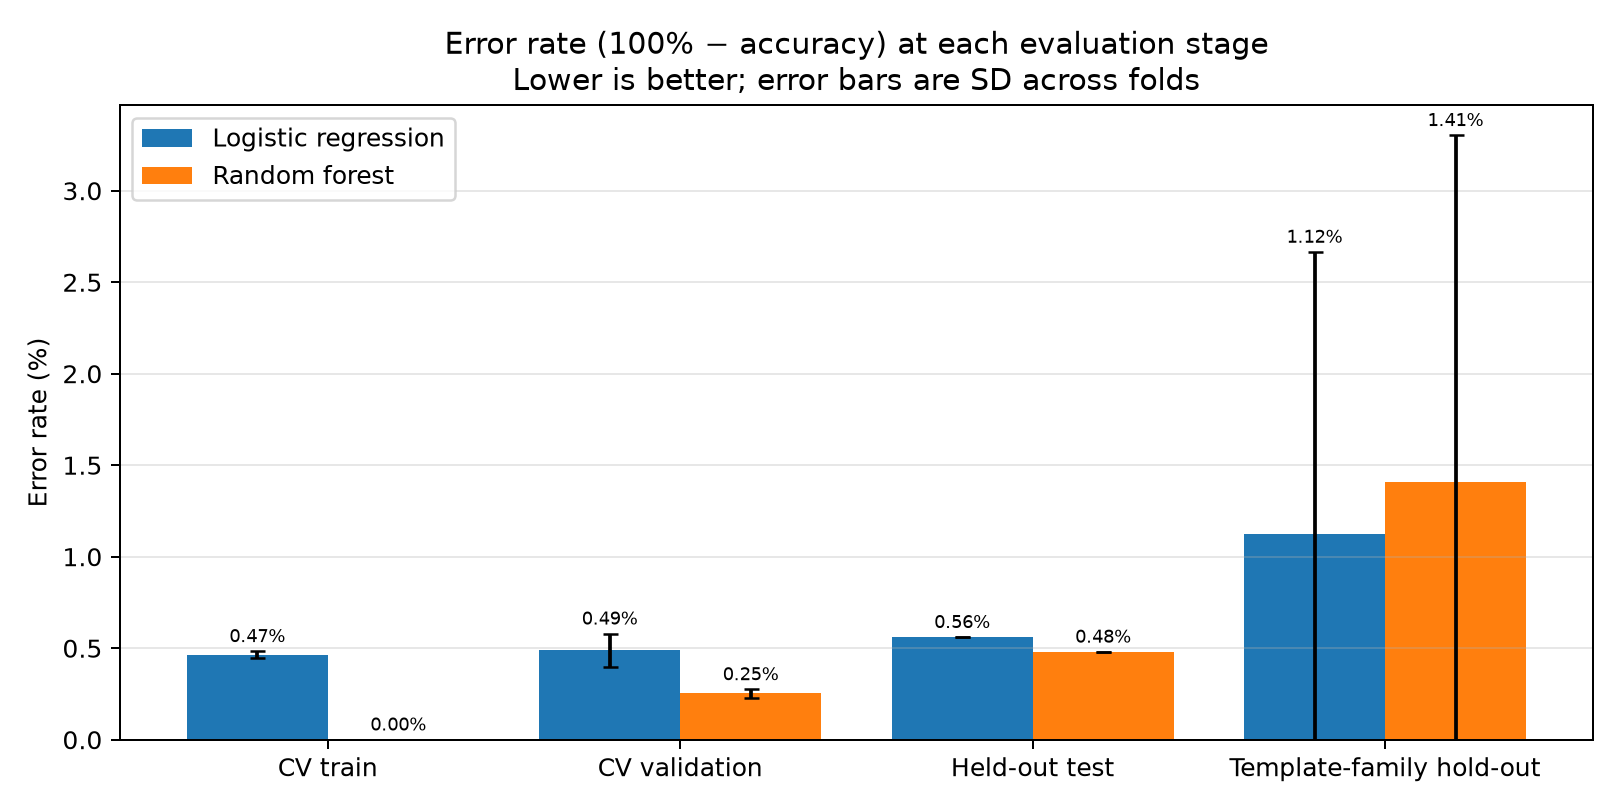

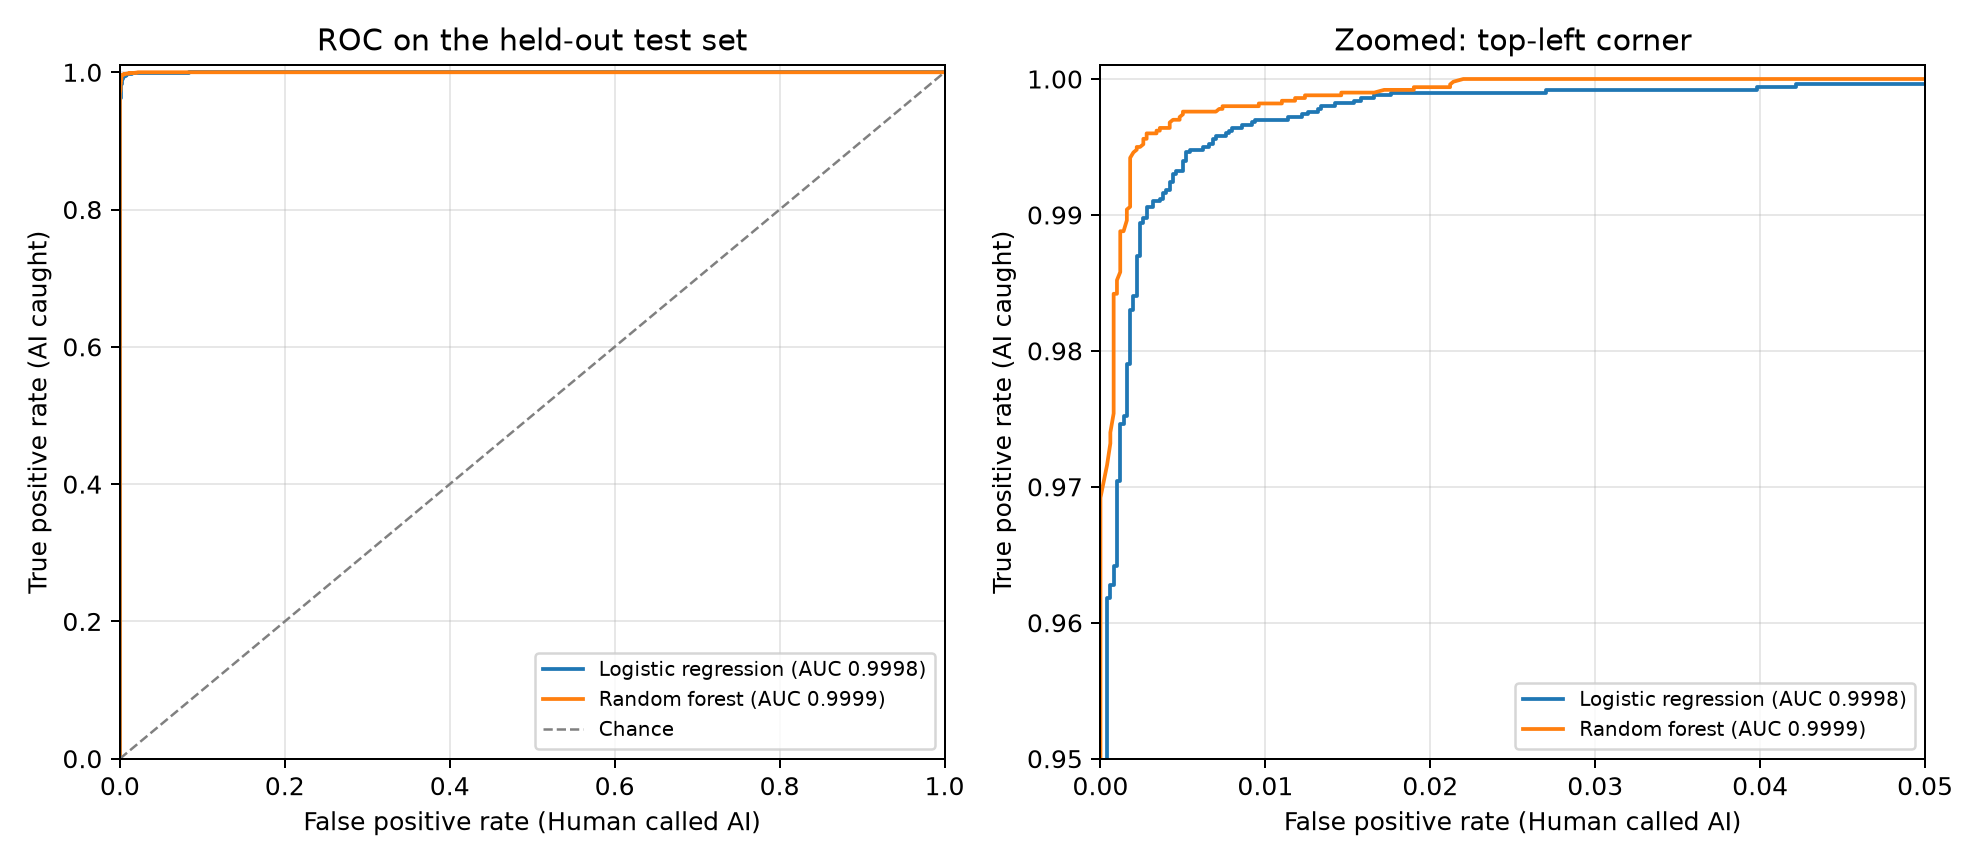

In [45]:
show("model_comparison_error_rates.png", 850)
show("model_comparison_roc.png", 950)

### Is the test-set difference real?

Both models were scored on the same 10,000 test texts. McNemar's test only counts texts
where exactly one model is wrong. If the models were equally good, those disagreements
would split about 50/50.

In [46]:
overlap = json.loads((METRICS / "model_comparison.json").read_text())
pair = overlap["logistic_regression_vs_random_forest"]
pd.Series({k: v for k, v in pair.items() if k != "both_wrong_text_ids"}).to_frame("value")

,value
test_rows,10000.000000
logistic_regression_errors,56.000000
random_forest_errors,48.000000
both_wrong,32.000000
only_logistic_regression_wrong,24.000000
only_random_forest_wrong,16.000000
mcnemar_exact_p_value,0.268187


### Error analysis: which texts fool the models?

In [47]:
from modeling import PROCESSED_PATH, SPLITS_PATH

lr = pd.read_csv(METRICS / "logistic_regression_test_predictions.csv")
rf = pd.read_csv(METRICS / "random_forest_test_predictions.csv")
splits = pd.read_csv(SPLITS_PATH, usecols=["Text_ID", "Template_Family_ID"])
both = lr.merge(rf, on=["Text_ID", "Label"], suffixes=("_LR", "_RF")).merge(splits, on="Text_ID")
both["LR_wrong"] = both["Predicted_Label_LR"] != both["Label"]
both["RF_wrong"] = both["Predicted_Label_RF"] != both["Label"]

by_family = both.groupby("Template_Family_ID").agg(
    label=("Label", lambda s: "AI" if s.iloc[0] == 1 else "Human"),
    test_rows=("Label", "size"),
    LR_errors=("LR_wrong", "sum"),
    RF_errors=("RF_wrong", "sum"),
)
by_family

,label,test_rows,LR_errors,RF_errors
Template_Family_ID,,,,
0,AI,1022,20,11
1,AI,992,0,0
2,AI,960,0,0
3,AI,1040,2,0
4,AI,986,0,0
5,Human,833,0,0
6,Human,831,0,0
7,Human,795,6,3
8,Human,791,0,0


In [48]:
processed = pd.read_csv(PROCESSED_PATH, usecols=["Text_ID", "Raw_Text", "Label_Name"])
shared = both[both["LR_wrong"] & both["RF_wrong"]].merge(processed, on="Text_ID")
print(f"Texts both models get wrong: {len(shared)}")
print(shared["Label_Name"].value_counts().to_string())
shared[["Text_ID", "Label_Name", "Template_Family_ID", "Probability_AI_LR", "Probability_AI_RF", "Raw_Text"]].head(8)

Texts both models get wrong: 32
Label_Name
Human    22
AI       10


,Text_ID,Label_Name,Template_Family_ID,Probability_AI_LR,Probability_AI_RF,Raw_Text
0,TXT_14945,Human,10,0.620794,0.740000,"When it comes to Business, there are several schools of thought-- The classi..."
1,TXT_15865,Human,10,0.685032,0.550000,"When it comes to Economics, there are several schools of thought. The classi..."
2,TXT_00179,Human,10,0.635775,0.743333,"When it comes to Cybersecurity, there are several schools of thought. The cl..."
3,TXT_06185,Human,10,0.772390,0.553333,"When it comes to Philosophy, there are several schools of thought. The appro..."
4,TXT_34151,Human,10,0.582445,0.780000,"When it comes to Productivity, there are several schools of thought. The cla..."
5,TXT_13636,Human,10,0.768708,0.663333,"When it comes to Cybersecurity, there are several schools of thought. The cl..."
6,TXT_39900,Human,10,0.977713,0.970000,"When it comes to Artificial Intelligence, there are several schools favors t..."
7,TXT_13174,Human,10,0.772390,0.553333,"When it comes to Psychology, there are several schools of thought. The the v..."


**What the errors show.** Almost every mistake from both models comes from two templates:
- **Family 10 (Human)** has the highest reading grade of the human templates (median about 12.2), so it's the closest human template to AI-style text.
- **Family 0 (AI)** has the lowest reading grade of the AI templates (median about 15.2), so it's the closest AI template to human-style text.

The other nine templates have zero or near-zero errors. The models fail where the two classes' writing styles overlap. Errors aren't random. That matches the feature
importances: reading grade level is the single strongest signal, and these are the two
templates where it's least clear-cut.

### Recommendation for the original benchmark (draft for team review)

| | Logistic regression | Random forest |
| --- | --- | --- |
| Held-out test error | 0.56% (56 texts) | 0.48% (48 texts) |
| Difference significant? | McNemar p ≈ 0.27, so **no** | |
| Unseen-template error | **1.12%** | 1.41% |
| Train vs. validation gap | none | 100% vs. 99.75% |
| Interpretability | signed coefficients | importances only |
| Training cost (tuning grid) | about 10 s | about 3 min |

**Recommended: logistic regression.** The random forest's small test-set advantage isn't
statistically significant. It does slightly worse on writing templates it hasn't seen,
which is the closest thing we have to new data. Logistic regression is also simpler,
faster, and directly explainable. The random forest is useful as confirmation: a much
more flexible model found almost no extra signal, and it ranked the same features as
most important. So the linear boundary is not leaving much on the table.

**Caveat for both models.** Near-perfect scores show that this benchmark's 11 templates
are separable by simple style statistics. They do **not** show that real human writing
and real LLM writing can be separated this well.

This recommendation covers the original benchmark only. Part 5 tests both models on a second, independent dataset, and **the overall recommendation is in Part 5.5**.

## Part 5. Second dataset: does it generalize? (M4)

The original benchmark is built from only 11 writing templates, so near-perfect scores there could
mean the models learned the templates, not human vs. AI writing. To test this we repeat steps 1–4
on **M4**, an independently collected, multi-domain research corpus, using **the same seven
features and the same modeling protocol**.

We ask two questions:
1. **Transfer:** do the original models work on M4 without retraining?
2. **Retraining:** how well can the same seven features do when the models are trained on M4?

Everything below reads the committed results in `reports/m4/`. They are produced by
`python run.py m4` (scripts `src/*_m4*.py`); the full method is in `docs/m4_dataset_review.md`.

### 5.1 Data understanding

**Source.** Kaggle mirror [`serjhenrique/m4-multi-generator-domain`](https://www.kaggle.com/datasets/serjhenrique/m4-multi-generator-domain),
version 1, of the [M4 research project](https://github.com/mbzuai-nlp/M4). 28 JSONL files cover five
domains (arXiv abstracts, peer reviews, Reddit, wikiHow, Wikipedia), human text, and six generators.

In [49]:
coverage = pd.read_csv(M4 / "coverage.csv")
print("Entries by domain and class in the raw files, before cleaning and deduplication:")
coverage.pivot_table(index="Domain", columns="Label_Name", values="Entries", aggfunc="sum")

Entries by domain and class in the raw files, before cleaning and deduplication:


Label_Name,AI,Human
Domain,,
arxiv,18000,18000
peerread,14060,41906
reddit,18000,18000
wikihow,15000,15000
wikipedia,14033,14033


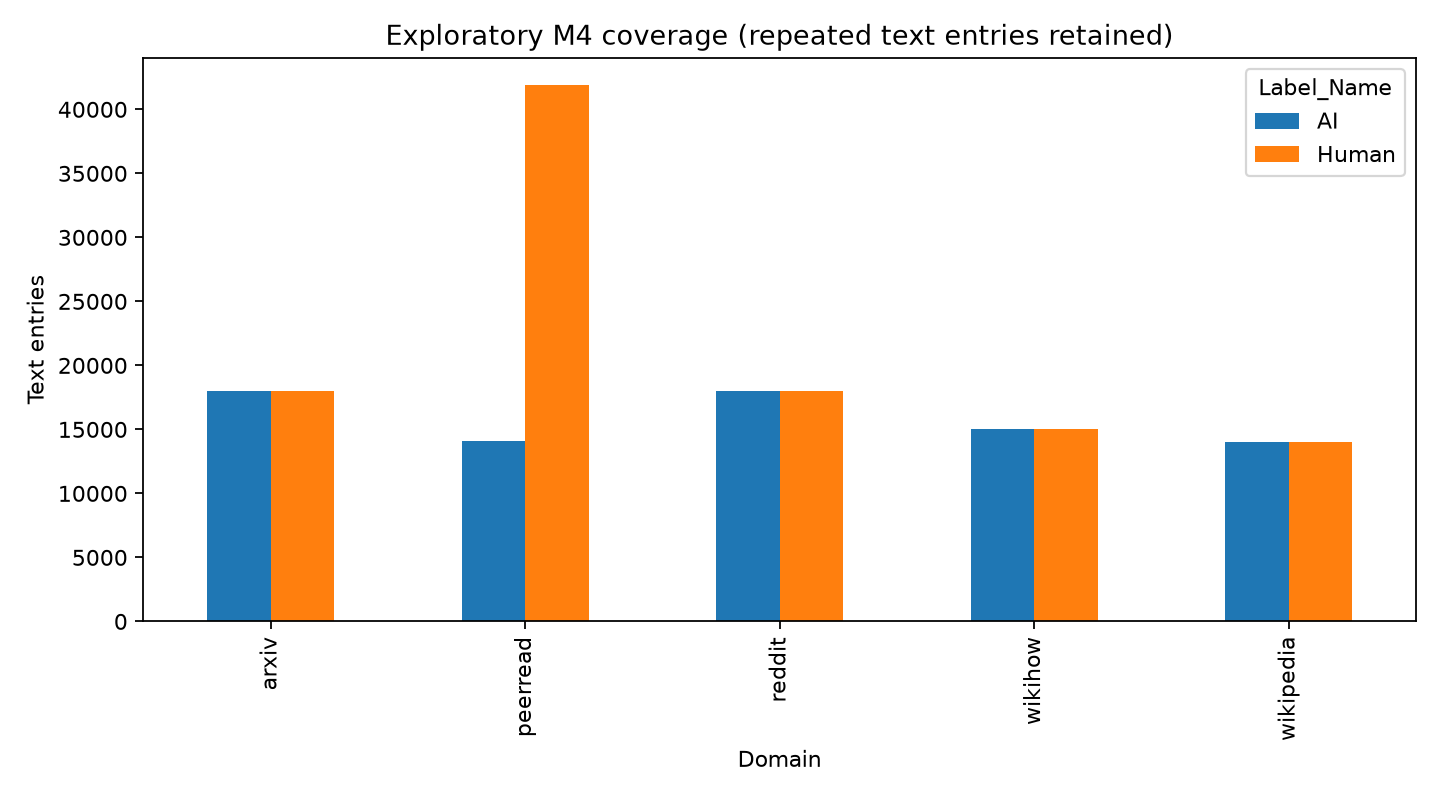

In [50]:
show("domain_class_coverage.png", 750, M4)

**Data-quality concerns found in the audit** (kept, documented, and grouped rather than silently deleted):
- Different files use different schemas; some records hold several passages or reviews.
- Some generations copy prompt text, repeat number sequences, or swap entities in a template.
- Source and generator metadata is inconsistent in places, and the mirror lists an "Unknown" license.
- The generators are older (for example GPT-3.5, davinci-003, BLOOMZ, Dolly), so M4 does not represent current models.

### 5.2 Preprocessing

Owner-approved rules: one passage or review per row; exclude empty entries; merge exact duplicate texts
while keeping every origin in a separate provenance table; **no length cuts and no downsampling**; the
same seven features. Row counts before and after each operation:

In [51]:
prep = json.loads((M4 / "preprocessing_summary.json").read_text())
display(pd.DataFrame(prep["operations"]))
print("Final rows:", sum(prep["class_counts"].values()), " class counts:", prep["class_counts"])

,operation,before,after
0,Expand passages/reviews,68548,186032
1,Exclude empty/null placeholders,186032,177111
2,"Consolidate exact duplicates, preserving every retained origin",177111,93435


Final rows: 93435  class counts: {'AI': 77287, 'Human': 16148}


**Class imbalance.** About 83% of M4 texts are AI. We did not rebalance by deleting texts. Instead,
we report metrics that expose the minority (Human) class: **balanced accuracy** and the
**Human false-positive rate** (the share of Human texts wrongly called AI). Accuracy alone would be
misleading, because always guessing "AI" scores 82.7%.

**Near-duplicates.** Every pair of the 93,435 texts (4.4 billion pairs) was compared by word-trigram
cosine similarity. Pairs at or above the owner-approved threshold of **0.85** are grouped with the
known related source texts. A group never crosses train/test or CV folds.

In [52]:
sim = json.loads((M4 / "similarity_review.json").read_text())
pd.DataFrame(sim["thresholds"]).set_index("threshold")

,near_duplicate_edges,combined_groups,largest_group,rows_in_multitext_groups
threshold,,,,
0.70,1267,13709,609,93434
0.75,992,13748,441,93434
0.80,757,13774,343,93434
0.85,532,13799,216,93434
0.90,366,13822,185,93434
0.95,251,13835,185,93434
0.99,207,13847,185,93434


In [53]:
split = json.loads((M4 / "split_summary.json").read_text())
partitions = pd.DataFrame(split["partitions"])
partitions["AI_proportion"] = partitions["AI_proportion"].round(4)
print(f"Groups: {split['groups']:,} (largest {split['largest_group']} texts). Check: {split['validation']}")
partitions

Groups: 13,799 (largest 216 texts). Check: No source or selected near-duplicate group crosses train/test or CV folds; both classes in every evaluation fold


,split,cv_fold,rows,groups,Human,AI,AI_proportion
0,test,-1,18678,2758,3230,15448,0.8271
1,train,0,14909,2199,2584,12325,0.8267
2,train,1,14943,2207,2584,12359,0.8271
3,train,2,14961,2210,2584,12377,0.8273
4,train,3,14978,2213,2583,12395,0.8275
5,train,4,14966,2212,2583,12383,0.8274


The same seven features distribute differently on M4. In particular, the Human/AI gaps in word length
and reading grade, which drove the original models, are much smaller:

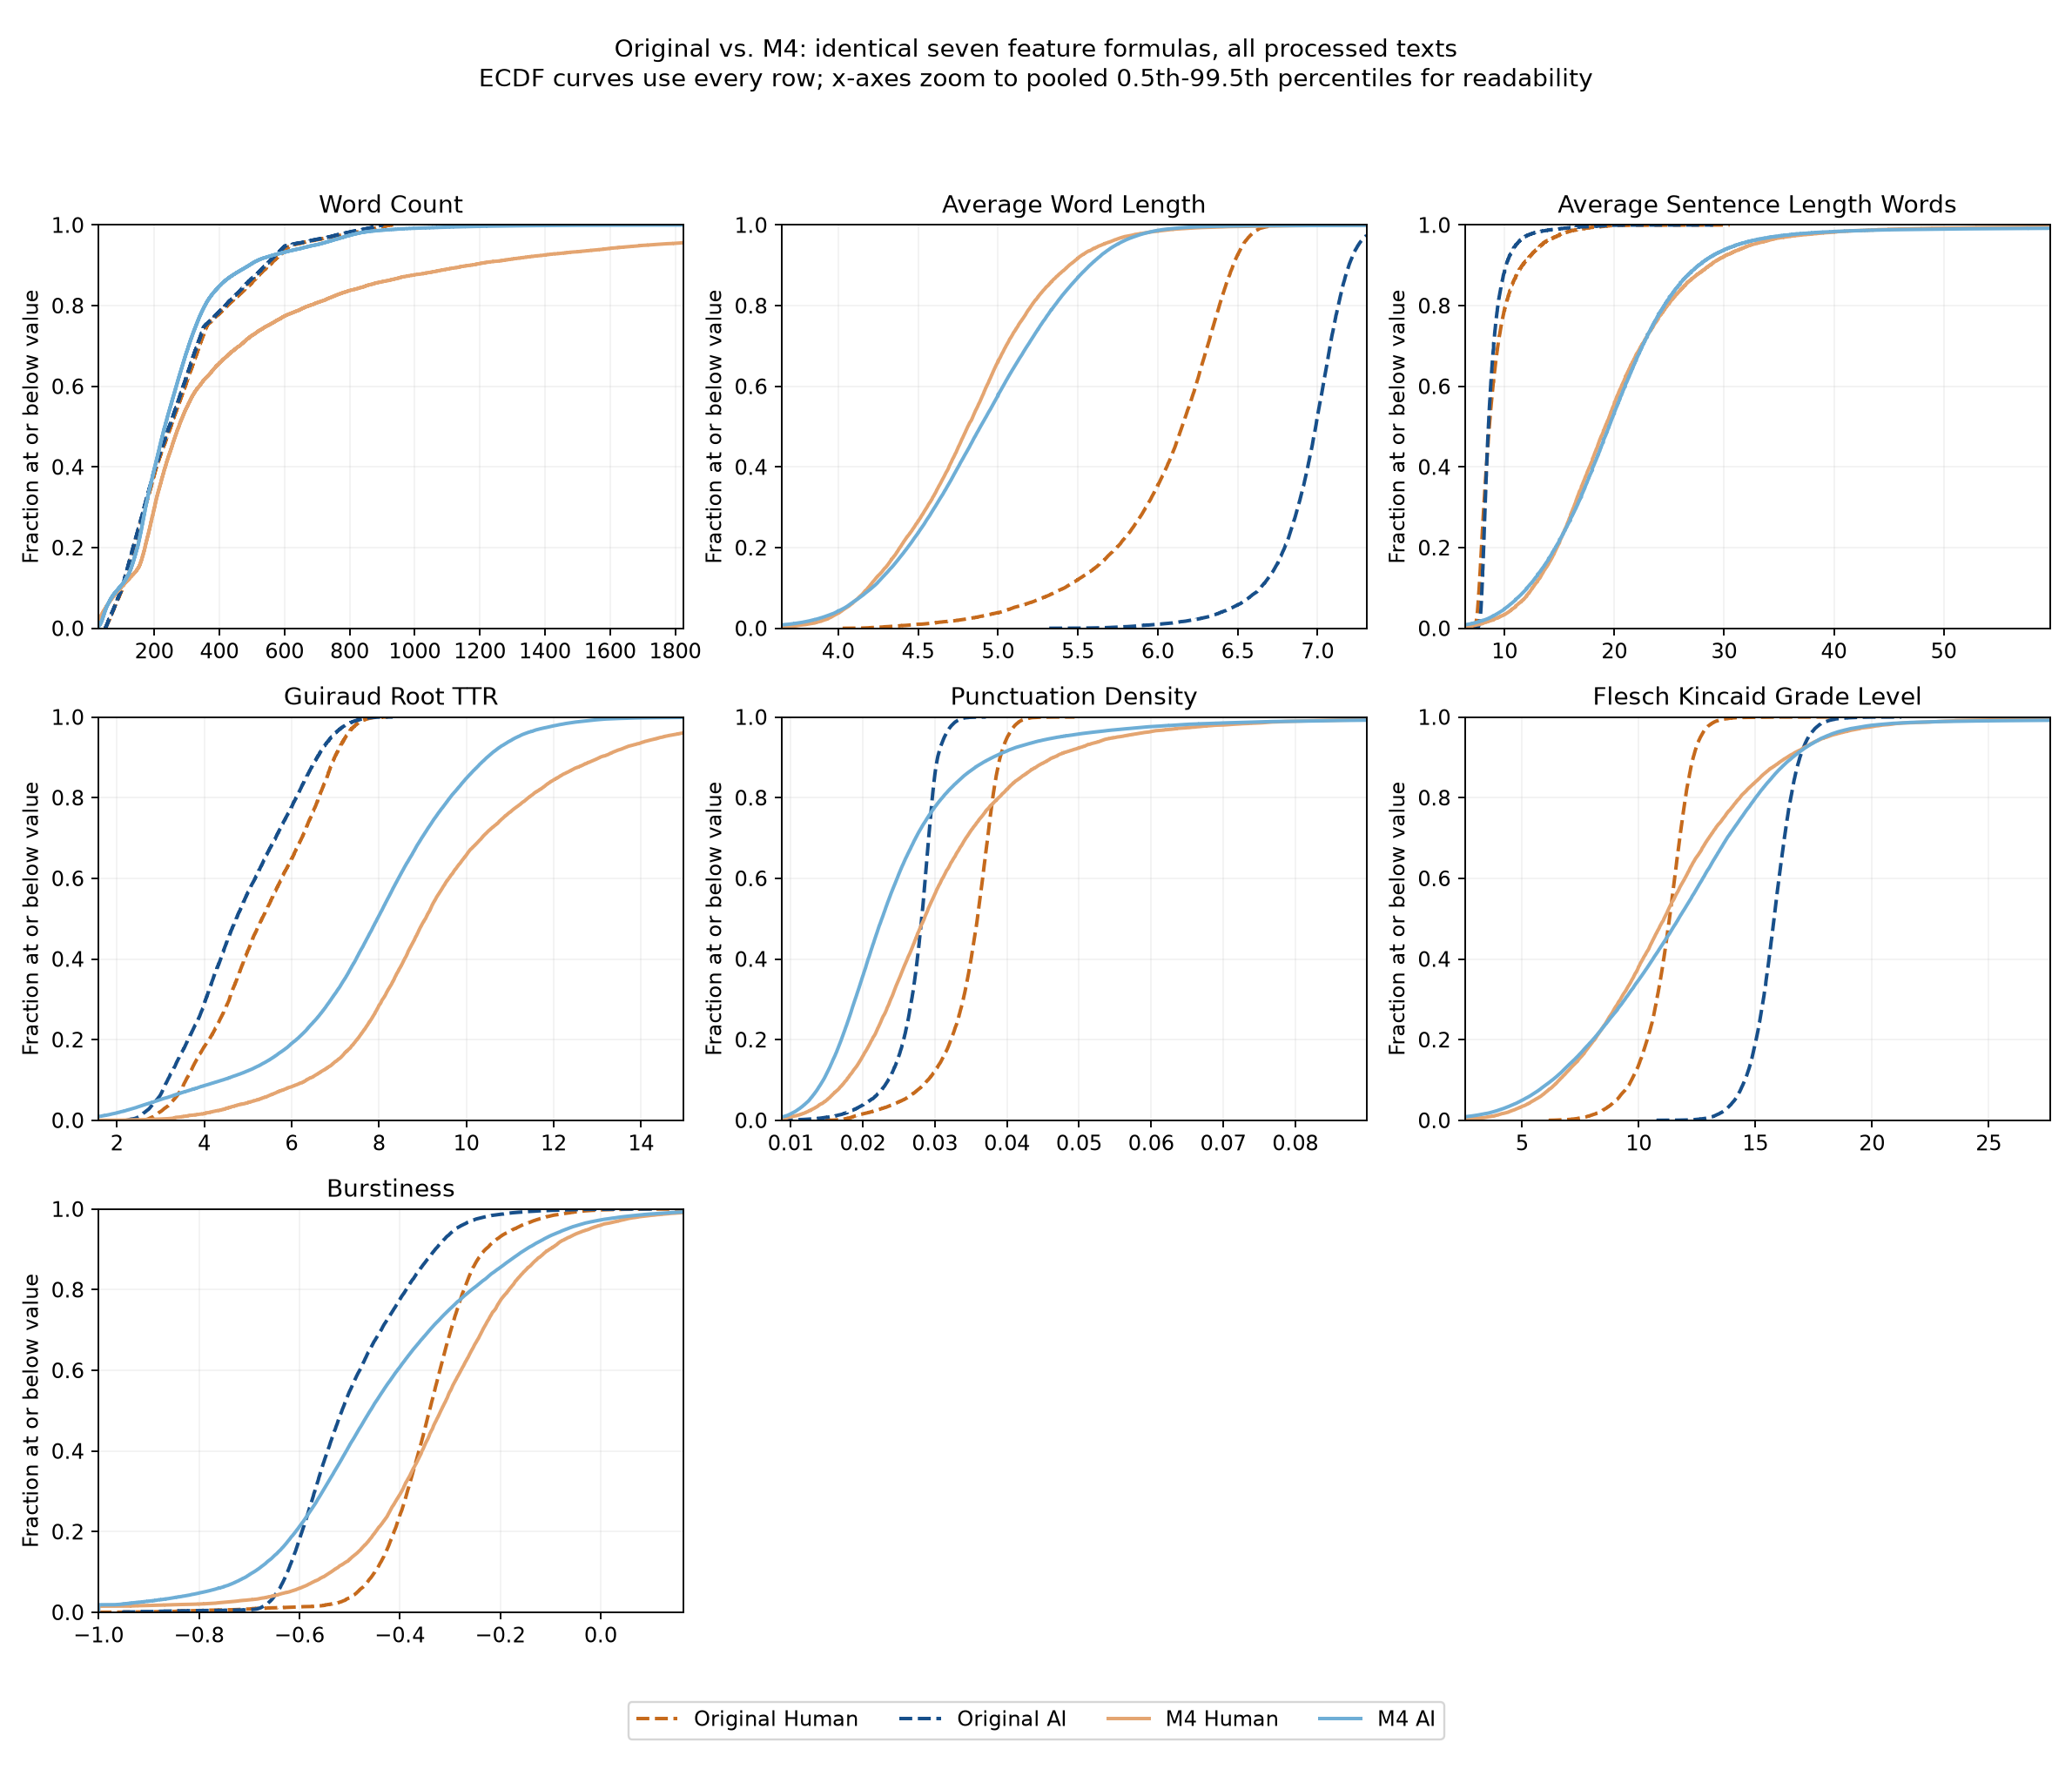

In [54]:
show("original_vs_m4_feature_distributions.png", 950, M4)

### 5.3 Models

Three evaluations, all on the **same 18,678 M4 test texts**:
- **Transfer:** the original logistic regression and random forest, applied with no refitting.
- **Logistic regression retrained on M4:** same pipeline and grid (`C` × L1/L2), tuned on the five M4 training folds by ROC-AUC.
- **Random forest retrained on M4:** same pipeline and grid (`max_depth` × `min_samples_leaf` × `max_features`, 300 trees), same folds. The search (180 fits) takes about 14 minutes with eight workers.

Both use the default 0.5 decision threshold and no class weighting, exactly like the original study.

In [55]:
def m4_metrics(name):
    path = M4 / f"{name}_metrics.json"
    return json.loads(path.read_text()) if path.exists() else None

stage_metrics = ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc", "human_false_positive_rate"]
rows = {}
for name, label in [("logistic_regression", "Logistic regression"), ("random_forest", "Random forest")]:
    result = m4_metrics(name)
    if result is None:
        print(f"{label}: not trained yet (python run.py m4)")
        continue
    print(f"{label}: best params {result['best_params']}, tuning + evaluation {result['fit_and_evaluation_seconds'] / 60:.1f} min")
    for stage, block in [("CV train (mean)", {m: v["mean"] for m, v in result["cv"]["train"].items()}),
                         ("CV validation (mean)", {m: v["mean"] for m, v in result["cv"]["validation"].items()}),
                         ("Full training set", result["train_metrics"]),
                         ("Held-out test", result["test_metrics"])]:
        rows[(label, stage)] = {m: block.get(m) for m in stage_metrics}
pd.DataFrame(rows).T.round(4).astype(object).fillna("—")

Logistic regression: best params {'clf__C': 1000.0, 'clf__l1_ratio': 1.0}, tuning + evaluation 0.5 min
Random forest: best params {'clf__max_depth': None, 'clf__max_features': 7, 'clf__min_samples_leaf': 10}, tuning + evaluation 13.7 min


accuracy balanced_accuracy precision  recall      f1 roc_auc human_false_positive_rate
Logistic regression CV train (mean)        0.8451                 —    0.8468  0.9922  0.9138   0.713                         —
                    CV validation (mean)   0.8452                 —    0.8469  0.9922  0.9138  0.7129                         —
                    Full training set      0.8451            0.5666    0.8469  0.9921  0.9138   0.713                    0.8589
                    Held-out test          0.8436             0.562    0.8453  0.9925   0.913  0.7103                    0.8684
Random forest       CV train (mean)        0.9251                 —    0.9265  0.9878  0.9562  0.9752                         —
                    CV validation (mean)   0.8787                 —    0.8944  0.9676  0.9296  0.9039                         —
                    Full training set      0.9261            0.8098    0.9278  0.9875  0.9567  0.9753                     0.368
                    Held-out test          0.8795            0.7153    0.8961  0.9663  0.9299  0.9078                    0.5356

**Over/underfitting.** Compare the CV train and validation rows for each model. A large gap means
overfitting; low scores on both mean underfitting (the features can't separate the classes well).

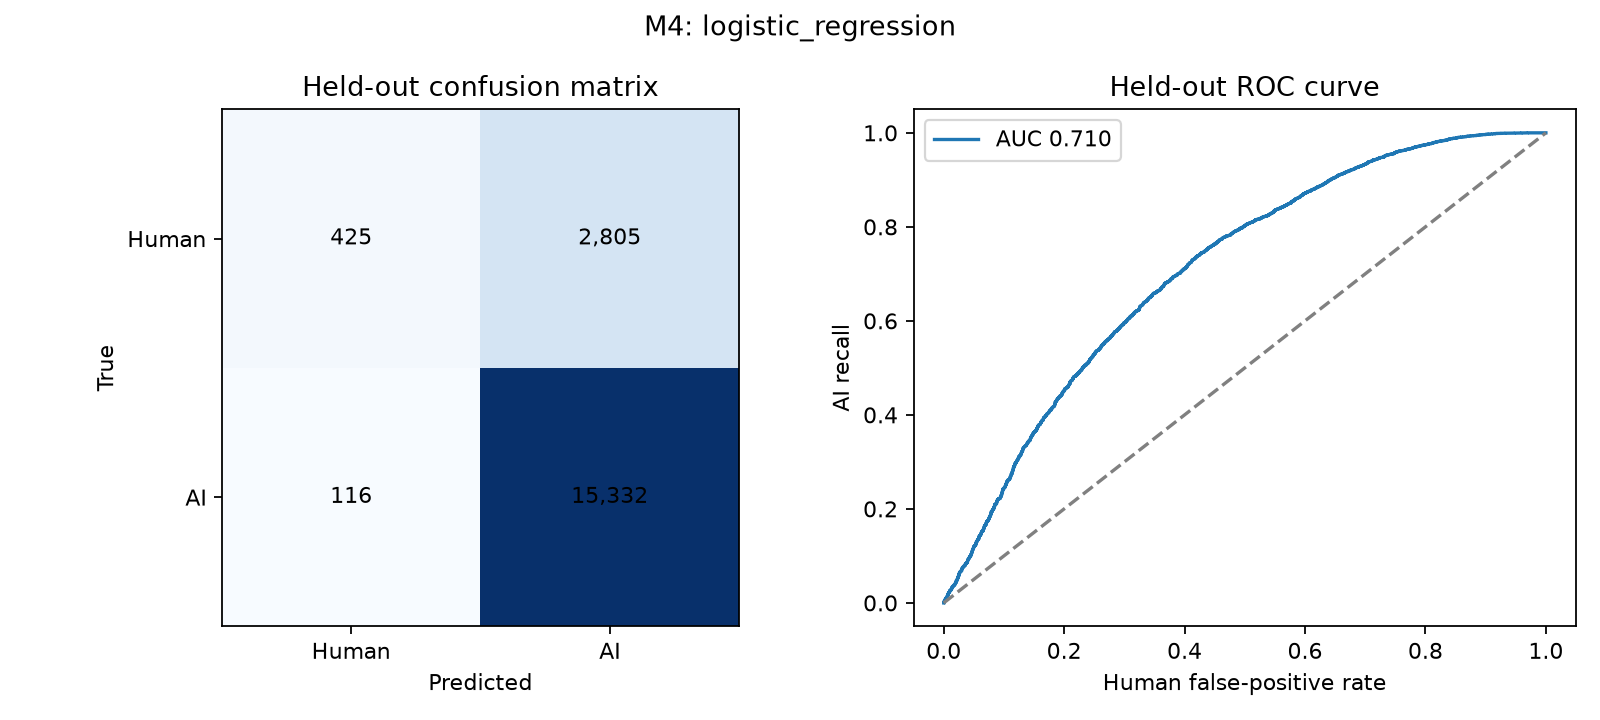

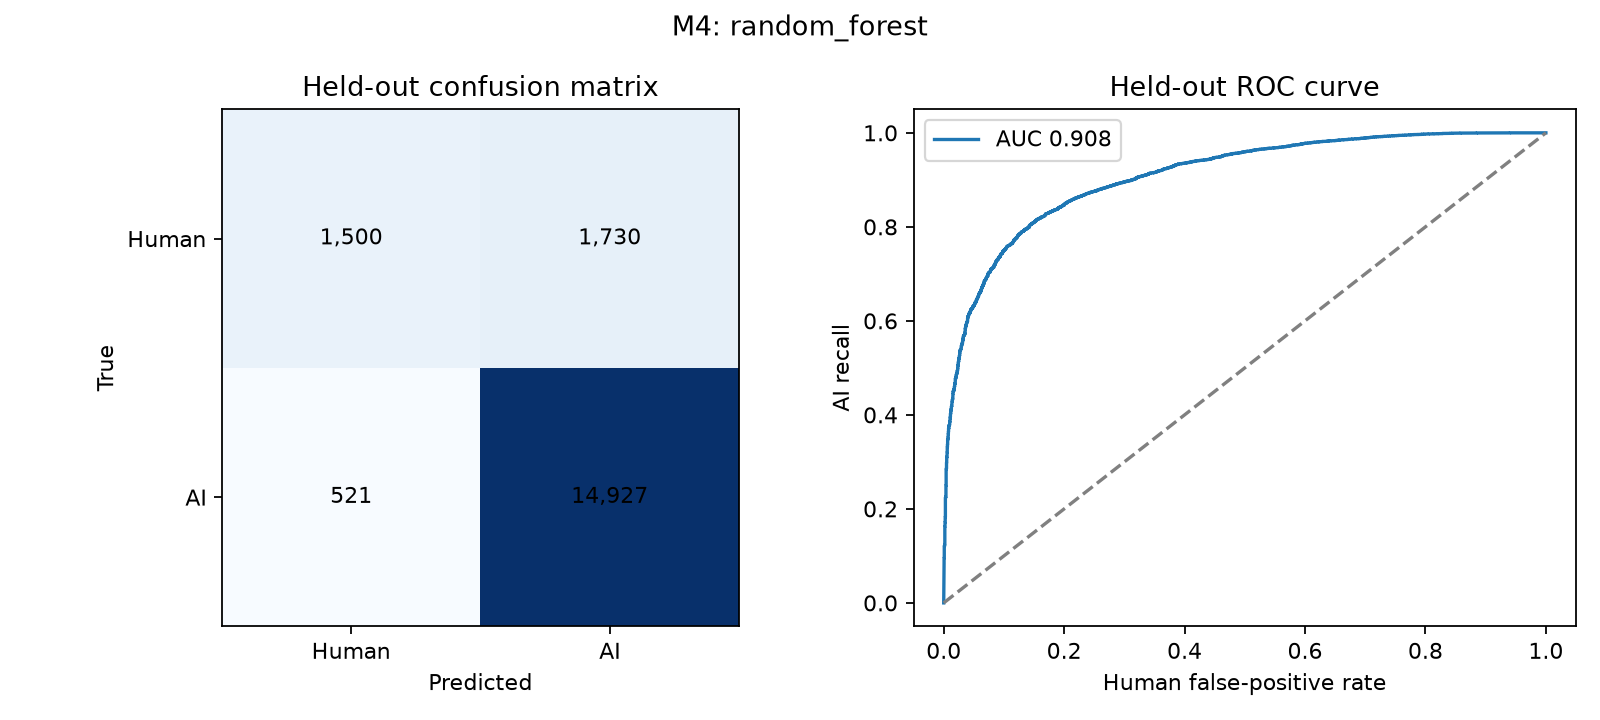

In [56]:
show("logistic_regression_evaluation.png", 900, M4)
if (M4 / "random_forest_evaluation.png").exists():
    show("random_forest_evaluation.png", 900, M4)

In [57]:
lr = m4_metrics("logistic_regression")
signals = pd.DataFrame({"LR standardized coefficient": lr["standardized_coefficients"]})
rf = m4_metrics("random_forest")
if rf is not None:
    signals["RF impurity importance"] = rf["training_impurity_importances"]
signals.round(3)

,LR standardized coefficient,RF impurity importance
Text_Word_Count,-0.372,0.326
Text_Average_Word_Length,0.704,0.078
Text_Average_Sentence_Length_Words,1.639,0.090
Text_Guiraud_Root_TTR,-0.484,0.203
Text_Punctuation_Density,-0.119,0.098
Text_Flesch_Kincaid_Grade_Level,-1.902,0.057
Text_Burstiness,-0.382,0.147


### 5.4 Evaluation and comparison

In [58]:
comparison = pd.read_csv(M4 / "model_comparison.csv")
columns = ["accuracy", "balanced_accuracy", "f1", "roc_auc", "human_false_positive_rate"]
print(f"Always guessing AI on the M4 test set: accuracy {lr['majority_class_test_accuracy']:.4f}, "
      "balanced accuracy 0.5, Human false-positive rate 1.0")
comparison.set_index(["model", "stage"])[columns].round(4)

Always guessing AI on the M4 test set: accuracy 0.8271, balanced accuracy 0.5, Human false-positive rate 1.0


accuracy  balanced_accuracy      f1  roc_auc  human_false_positive_rate
model               stage                                                                                                           
logistic_regression Original benchmark test (reconstructed)    0.9944             0.9944  0.9944   0.9998                     0.0068
                    Transfer to M4                             0.2908             0.5374  0.2724   0.6221                     0.0858
                    Retrained on M4                            0.8436             0.5620  0.9130   0.7103                     0.8684
random_forest       Original benchmark test (reconstructed)    0.9952             0.9952  0.9952   0.9999                     0.0074
                    Transfer to M4                             0.1942             0.5004  0.0622   0.6119                     0.0316
                    Retrained on M4                            0.8795             0.7153  0.9299   0.9078                     0.5356

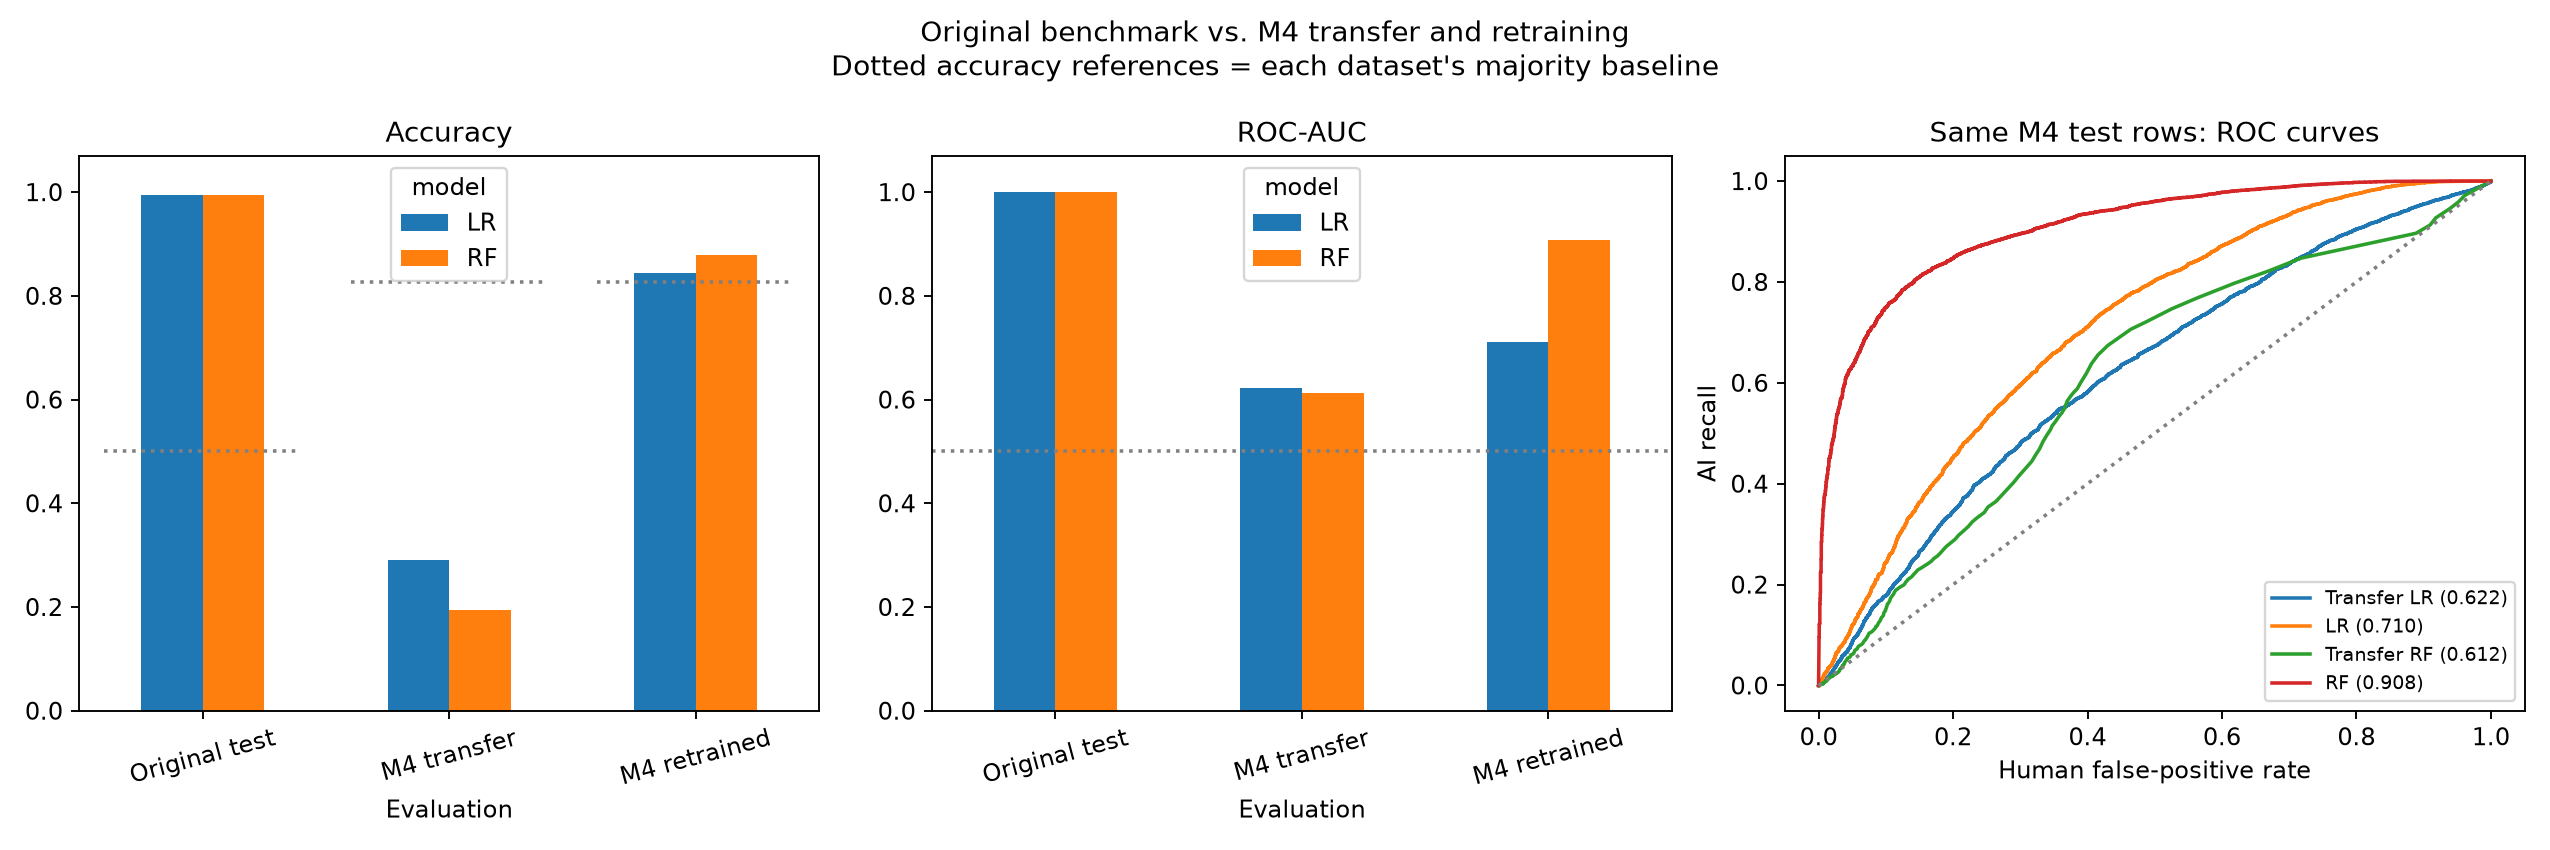

In [59]:
show("study_model_comparison.png", 950, M4)

**Uncertainty.** 95% intervals from a paired bootstrap that resamples whole test groups (so related
texts stay together). They are conditional on the fixed models and split.

In [60]:
boot = json.loads((M4 / "group_bootstrap_intervals.json").read_text())
interval_rows = {}
for model, metrics in boot["models"].items():
    for metric in ["balanced_accuracy", "roc_auc", "human_false_positive_rate"]:
        v = metrics[metric]
        interval_rows[(model, metric)] = f"{v['estimate']:.3f}  [{v['lower_95']:.3f}, {v['upper_95']:.3f}]"
display(pd.Series(interval_rows).unstack())
differences = {(pair, metric): f"{v['estimate']:+.3f}  [{v['lower_95']:+.3f}, {v['upper_95']:+.3f}]"
               for pair, metrics in boot["paired_differences"].items() for metric, v in metrics.items()}
pd.Series(differences).unstack()

,balanced_accuracy,human_false_positive_rate,roc_auc
logistic_regression,"0.562 [0.557, 0.568]","0.868 [0.856, 0.879]","0.710 [0.700, 0.721]"
random_forest,"0.715 [0.707, 0.726]","0.536 [0.514, 0.554]","0.908 [0.903, 0.913]"
transfer_logistic_regression,"0.537 [0.531, 0.543]","0.086 [0.077, 0.097]","0.622 [0.613, 0.630]"
transfer_random_forest,"0.500 [0.497, 0.504]","0.032 [0.026, 0.038]","0.612 [0.601, 0.621]"


,accuracy,balanced_accuracy,f1,human_false_positive_rate,roc_auc
LR retrained minus transfer,"+0.553 [+0.543, +0.562]","+0.025 [+0.017, +0.034]","+0.641 [+0.625, +0.656]","+0.783 [+0.766, +0.796]","+0.088 [+0.076, +0.099]"
RF retrained minus transfer,"+0.685 [+0.678, +0.691]","+0.215 [+0.205, +0.225]","+0.868 [+0.860, +0.874]","+0.504 [+0.482, +0.524]","+0.296 [+0.287, +0.307]"
Retrained RF minus LR,"+0.036 [+0.032, +0.040]","+0.153 [+0.146, +0.162]","+0.017 [+0.015, +0.019]","-0.333 [-0.351, -0.317]","+0.198 [+0.188, +0.209]"


**Error analysis by domain.** Human false-positive rate per domain on the test set:

In [61]:
errors = pd.read_csv(M4 / "test_errors_by_domain.csv")
display(errors.pivot(index="domain", columns="model", values="human_false_positive_rate").round(3))
errors.pivot(index="domain", columns="model", values="roc_auc").round(3)

model,logistic_regression,random_forest,transfer_logistic_regression,transfer_random_forest
domain,,,,
arxiv,1.000,0.779,0.243,0.020
peerread,0.965,0.651,0.071,0.019
reddit,0.853,0.368,0.005,0.000
wikihow,0.719,0.367,0.002,0.000
wikipedia,0.825,0.519,0.099,0.091


model,logistic_regression,random_forest,transfer_logistic_regression,transfer_random_forest
domain,,,,
arxiv,0.718,0.836,0.555,0.575
peerread,0.659,0.927,0.753,0.713
reddit,0.891,0.962,0.759,0.738
wikihow,0.720,0.922,0.697,0.598
wikipedia,0.639,0.883,0.525,0.497


### 5.5 Recommendation

**Over- and underfitting on M4.** The two models fail in opposite ways. Logistic regression's training
and validation ROC-AUC are equal (about 0.71), so it **underfits**: a linear boundary on these seven
features can't separate M4's classes. The random forest has a moderate train/validation gap
(0.975 vs. 0.904), so it partly memorizes the training data, but its validation score matches the
untouched test score (0.908). The gap doesn't make its estimate unreliable.

**Recommended model: random forest.**

| | Logistic regression | Random forest |
| --- | --- | --- |
| M4 test ROC-AUC | 0.710 | **0.908** |
| Balanced accuracy | 0.562 | **0.715** |
| Human texts wrongly called AI | 86.8% | **53.6%** |
| Paired bootstrap, RF − LR | | every interval excludes zero |
| Train vs. validation | underfits (equal, low) | moderate gap, validation = test |
| Tuning time here | under 1 min | about 14 min |
| Interpretability | signed coefficients | importances only |

On the original benchmark we preferred logistic regression (Part 4), because both models were equally
accurate there and LR was simpler. M4 is the more realistic test, and it reverses that: the forest's
flexibility is what lets the same seven features carry real signal. **Caveat:** neither model is a
usable detector at the default 0.5 threshold, since even the forest wrongly flags about half of Human
texts. Threshold selection and class weighting are the next steps.

## Part 6. Conclusions and limitations

- **On the original benchmark**, both models reach about 99.5% accuracy, but that benchmark is 11
  single-class templates. The models learned to tell those templates apart.
- **On M4**, the original models fail to transfer (accuracy 19–29%, ROC-AUC about 0.61–0.62).
  Retrained on M4, logistic regression underfits (ROC-AUC 0.71) while the random forest reaches
  ROC-AUC 0.91. Even the forest, at the 0.5 threshold and without class weighting, wrongly flags
  about half of Human texts.
- **Recommended model: random forest**, because it is clearly better on the realistic test (Part 5.5).
- **What we learned:** a near-perfect score on one benchmark is not evidence of a general AI-text
  detector. Testing on an independent corpus was necessary to see this.
- **Limitations:** seven hand-built features; fixed 0.5 threshold; no class weighting; M4 uses older
  generators and has some noisy generations; grouping limits but does not rule out related content
  across splits.
- **Next steps:** class weighting and a threshold chosen on training folds (to lower Human false
  positives), domain/generator hold-outs, and richer text representations. See `docs/HANDOFF.md`.